In [1]:
import os, kagglehub

DATA_DIR = os.path.join(kagglehub.dataset_download("mostafaabla/garbage-classification"), "garbage_classification")
CLASSES = sorted(os.listdir(DATA_DIR))
print(DATA_DIR, len(CLASSES), '클래스,', sum(len(os.listdir(os.path.join(DATA_DIR, c))) for c in CLASSES), '장')

Using Colab cache for faster access to the 'garbage-classification' dataset.
/kaggle/input/garbage-classification/garbage_classification 12 클래스, 15515 장


### 0. 저장 위치 설정

In [2]:
import shutil

if os.path.exists('/content/drive/MyDrive') :
    SAVE_DIR = '/content/drive/MyDrive/bigdata/cache'     # Drive 안에 저장함 (연결이 끊겨도 남음)
    if os.path.isdir('cache') :                             # Drive 연결 전에 서버 안에 저장해 둔 결과가 있으면
        shutil.copytree('cache', SAVE_DIR, dirs_exist_ok = True)   # Drive로 복사하고
        shutil.rmtree('cache')                              # 서버 안의 것은 지움 (Run All 때마다 다시 복사하지 않게)
        print('서버 안 cache 폴더의 결과를 Drive로 옮김')
elif os.path.exists('/content') :                          # Colab인데 Drive가 연결 안 된 경우
    SAVE_DIR = 'cache'                                      # 서버 안에 저장함 (서버가 끊기면 지워짐)
    print('주의: Drive가 연결되지 않아 서버 안에만 저장함 → 서버 연결이 끊기면 지워짐')
else :                                                      # 내 PC에서 실행하는 경우 (Colab이 아님)
    SAVE_DIR = os.path.join(os.path.expanduser('~'), 'bigdata_cache')   # OneDrive 밖에 저장함 (C:\Users\사용자\bigdata_cache)

os.makedirs(SAVE_DIR, exist_ok = True)                      # 폴더가 없으면 만듦
print('저장 위치:', SAVE_DIR)
print('저장된 파일:', sorted(os.listdir(SAVE_DIR)))          # 지금까지 저장된 결과 목록

주의: Drive가 연결되지 않아 서버 안에만 저장함 → 서버 연결이 끊기면 지워짐
저장 위치: cache
저장된 파일: []


# EDA

### 1-1. 데이터 구조 확인

In [4]:
import os
import pandas as pd

# 이미지 경로와 클래스 이름을 표(df) 하나로 정리 → 이후 EDA는 모두 이 표를 사용
rows = []
for c in CLASSES:                                       # 클래스 폴더를 하나씩
    for f in os.listdir(os.path.join(DATA_DIR, c)):     # 그 폴더 안의 파일을 하나씩
        rows.append([os.path.join(DATA_DIR, c, f), c])  # [파일 경로, 클래스 이름]
df = pd.DataFrame(rows, columns=['path', 'label'])

print('전체 장수:', len(df))
print('클래스 수:', df['label'].nunique())

# 확장자 종류 확인 (jpg 말고 다른 형식이 섞여 있는지)
print(df['path'].str.split('.').str[-1].str.lower().value_counts())
df.head()


전체 장수: 15515
클래스 수: 12
path
jpg    15515
Name: count, dtype: int64


,path,label
0,/kaggle/input/garbage-classification/garbage_c...,battery
1,/kaggle/input/garbage-classification/garbage_c...,battery
2,/kaggle/input/garbage-classification/garbage_c...,battery
3,/kaggle/input/garbage-classification/garbage_c...,battery
4,/kaggle/input/garbage-classification/garbage_c...,battery


**관찰**
- 12클래스, 15,515장이고 파일은 전부 jpg임
- 데이터 카드에는 15,150장으로 적혀 있지만 실제 파일 수는 15,515장임 → 실제 개수 기준으로 진행함

**시사점**
- 폴더 이름 = 클래스 이름 구조라서 폴더를 그대로 읽으면 됨

### 1-2. 클래스 분포 (불균형 확인)

             count  ratio(%)
label                       
clothes       5325      34.3
shoes         1977      12.7
paper         1050       6.8
biological     985       6.3
battery        945       6.1
cardboard      891       5.7
plastic        865       5.6
white-glass    775       5.0
metal          769       5.0
trash          697       4.5
green-glass    629       4.1
brown-glass    607       3.9
최대/최소 비율: 8.8


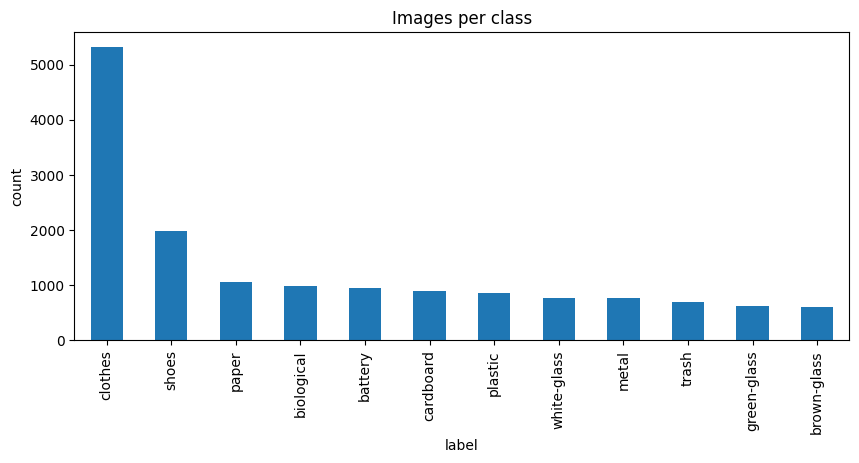

In [5]:
import matplotlib.pyplot as plt

counts = df['label'].value_counts()          # 클래스별 장수 (많은 순)
ratio = (counts / len(df) * 100).round(1)    # 전체 대비 비율(%)
print(pd.DataFrame({'count': counts, 'ratio(%)': ratio}))

# 가장 많은 클래스가 가장 적은 클래스의 몇 배인지 = 불균형 정도
print('최대/최소 비율:', round(counts.max() / counts.min(), 1))

counts.plot.bar(figsize=(10, 4), title='Images per class')
plt.ylabel('count')
plt.show()


**관찰**
- clothes 34.3%, shoes 12.7%로 두 클래스가 전체의 47%를 차지함
- 가장 적은 brown-glass는 3.9%이고, 최대/최소 비율이 8.8배임

**시사점**
- clothes만 다 맞혀도 accuracy가 34%부터 시작함 → accuracy만으로는 성능을 판단할 수 없음
- 모든 클래스를 똑같이 반영하는 **macro-F1을 주지표**로 씀
- train/val/test 분할은 **층화 분할**로 해야 소수 클래스가 각 세트에 비율대로 들어감
- 불균형 처리(클래스 가중치, 가중 샘플링)는 효과를 실험으로 비교할 후보로 둠

### 1-3. 클래스별 샘플 이미지 보기

In [6]:
from PIL import Image

n = 8   # 클래스마다 보여줄 장수
fig, axes = plt.subplots(len(CLASSES), n, figsize=(n * 1.6, len(CLASSES) * 1.7))

for i, c in enumerate(CLASSES):                                       # i행 = i번째 클래스
    paths = df[df['label'] == c]['path'].sample(n, random_state=42)  # 클래스에서 무작위 n장 (매번 같은 n장)
    for j, p in enumerate(paths):
        axes[i, j].imshow(Image.open(p).convert('RGB'))               # RGB로 바꿔서 표시
        axes[i, j].axis('off')
    axes[i, 0].set_title(c, loc='left', fontsize=9)                   # 각 행의 첫 칸에 클래스 이름

plt.tight_layout()
plt.show()


Output hidden; open in https://colab.research.google.com to view.

**관찰**
- 클래스마다 촬영 출처·배경이 다름
  - trash, white-glass, battery, brown-glass: 흰 배경의 상품·스톡 사진이 많고 워터마크도 보임
  - metal, plastic, cardboard 일부: 같은 베이지·연보라 배경에서 찍은 실제 쓰레기 사진임
  - clothes: 바닥·침대 위의 옷 사진 / biological: 썩은 음식보다 신선한 음식 사진이 많음
- 한 클래스 안의 다양성이 큼 (battery에 휴대폰·보조·노트북·자동차 배터리가 섞여 있음)
- 사람이 봐도 헷갈리는 쌍이 있음: white-glass ↔ plastic(투명 병), paper ↔ cardboard

**시사점**
- 모델이 물체 대신 **배경·촬영 스타일로 클래스를 맞히는 지름길**을 배울 위험이 있음 → 보고서 한계로 기록함
- 배경 의존을 줄이는 증강(무작위 자르기·확대, 밝기 변화)이 의미 있음
- 오류 분석에서 white-glass ↔ plastic, paper ↔ cardboard를 집중해서 봄

### 1-4. 이미지 크기와 색 모드

mode
RGB    15481
P         34
Name: count, dtype: int64
          width    height    aspect
count  15515.00  15515.00  15515.00
mean     349.82    351.71      1.08
std      117.55    149.42      0.35
min       51.00    100.00      0.13
25%      234.00    224.00      0.75
50%      400.00    384.00      1.00
75%      400.00    533.00      1.33
max      888.00    936.00      5.02


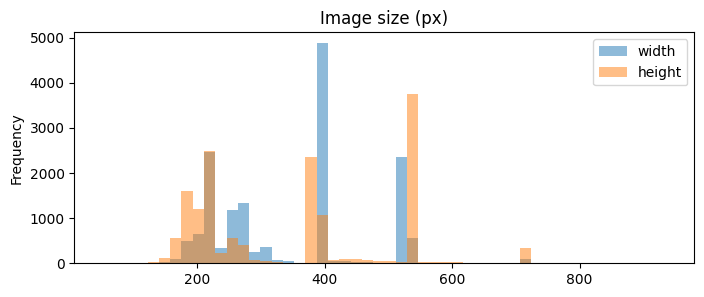

In [7]:
widths, heights, modes = [], [], []
for p in df['path']:
    with Image.open(p) as im:       # 파일 정보(헤더)만 읽어서 빠름
        widths.append(im.width)
        heights.append(im.height)
        modes.append(im.mode)       # RGB(컬러), RGBA(투명도 포함), L(흑백), P(팔레트) 등

df['width'] = widths
df['height'] = heights
df['mode'] = modes
df['aspect'] = df['width'] / df['height']   # 가로/세로 비율 (1이면 정사각형)

print(df['mode'].value_counts())                       # RGB가 아닌 이미지가 있는지
print(df[['width', 'height', 'aspect']].describe().round(2))

# 크기 분포 그래프 (너무 큰 값은 2000으로 잘라서 보기 쉽게)
df[['width', 'height']].clip(upper=2000).plot.hist(bins=50, alpha=0.5, figsize=(8, 3), title='Image size (px)')
plt.show()


**관찰**
- 크기 중앙값은 약 400×384px이고 가장 큰 이미지도 936px임 (대부분 작은 이미지임)
- 가로/세로 비율은 중간 50%가 0.75~1.33이지만 0.13, 5.02 같은 극단값도 있음
- 34장이 RGB가 아닌 P(팔레트) 모드임

**시사점**
- 입력 크기는 128~224px면 원본 정보를 크게 잃지 않음
- **모든 이미지를 RGB로 변환하는 단계가 반드시 필요함** (안 하면 P 모드 이미지에서 오류가 남)

### 1-5. 클래스별 평균 색

                 R      G      B  brightness
label                                       
battery      187.3  187.1  187.2       187.2
biological   165.0  140.5  112.4       139.3
brown-glass  186.5  173.5  163.5       174.5
cardboard    186.3  168.1  147.6       167.3
clothes      136.3  119.3  111.4       122.3
green-glass  162.0  183.3  155.0       166.8
metal        175.1  168.3  165.7       169.7
paper        177.5  168.5  161.2       169.1
plastic      183.4  186.4  188.4       186.1
shoes        168.6  157.2  148.6       158.1
trash        216.9  221.1  222.3       220.1
white-glass  203.6  202.7  201.0       202.4


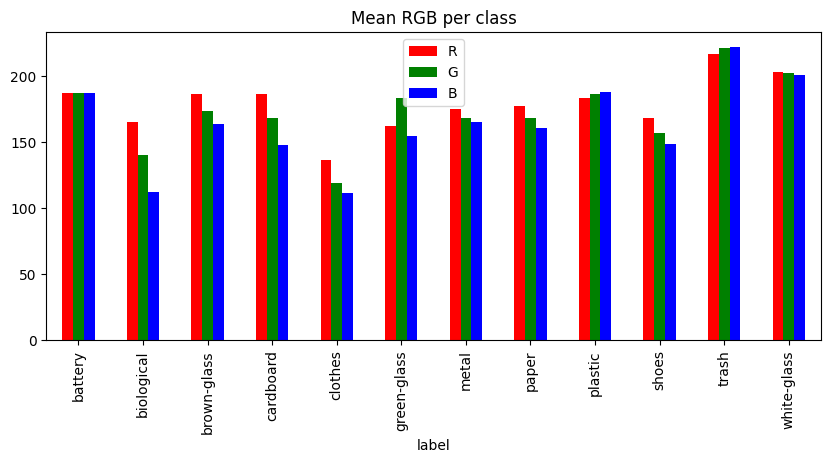

In [8]:
import numpy as np

# 전부 계산하면 오래 걸려서 클래스당 100장만 뽑아 계산
sample = df.groupby('label').sample(100, random_state=42)

means = []
for p in sample['path']:
    img = Image.open(p).convert('RGB').resize((64, 64))   # 작게 줄여서 계산 속도 향상
    arr = np.array(img).reshape(-1, 3)                     # (픽셀 수, 3) 모양으로 펼침
    means.append(arr.mean(axis=0))                         # 이미지 한 장의 평균 R, G, B

sample[['R', 'G', 'B']] = np.array(means)
color = sample.groupby('label')[['R', 'G', 'B']].mean().round(1)   # 클래스별 평균 색
color['brightness'] = color.mean(axis=1).round(1)                  # R, G, B 평균 = 밝기
print(color)

color[['R', 'G', 'B']].plot.bar(color=['red', 'green', 'blue'], figsize=(10, 4), title='Mean RGB per class')
plt.show()


**관찰** (클래스당 100장 표본, random_state=42 기준)
- green-glass는 G가 가장 높고, brown-glass는 R > G > B 순임 → 유리 3종이 색으로 갈림
- plastic(183/186/188)과 white-glass(204/203/201)는 둘 다 무채색이고 밝아서 색으로 잘 구분되지 않음
- 가장 밝은 클래스는 trash(220)·white-glass(202)로 흰 배경 사진이 많기 때문이고, 가장 어두운 클래스는 clothes(122)임

**시사점**
- **색조(hue) 변경·흑백 변환 증강은 쓰면 안 됨** → 유리 3종은 색 자체가 정답이기 때문임
- 클래스마다 배경 밝기가 다르므로 밝기·대비 증강이 배경 지름길을 줄이는 데 도움이 될 수 있음
- plastic ↔ white-glass는 색이 아니라 모양·질감으로 구분해야 해서 가장 어려운 쌍이 될 것으로 예상함

### 1-6. 중복 · 깨진 파일 확인

In [9]:
import hashlib

hashes, broken = [], []
for p in df['path']:
    with open(p, 'rb') as f:
        hashes.append(hashlib.md5(f.read()).hexdigest())   # 파일 내용이 똑같으면 같은 값이 나옴
    try:
        Image.open(p).verify()   # 깨진 이미지면 여기서 오류가 남
    except Exception:
        broken.append(p)

df['md5'] = hashes

# 같은 md5를 가진 이미지 = 완전히 같은 파일
dup = df[df.duplicated('md5', keep=False)].sort_values('md5')
print('중복에 포함된 이미지:', len(dup), '장 /', dup['md5'].nunique(), '그룹')
print('서로 다른 클래스끼리 중복:', (dup.groupby('md5')['label'].nunique() > 1).sum(), '그룹')
print('깨진 이미지:', len(broken))
dup[['path', 'label']].head(10)


중복에 포함된 이미지: 37 장 / 18 그룹
서로 다른 클래스끼리 중복: 3 그룹
깨진 이미지: 0


,path,label
9330,/kaggle/input/garbage-classification/garbage_c...,green-glass
9209,/kaggle/input/garbage-classification/garbage_c...,green-glass
9206,/kaggle/input/garbage-classification/garbage_c...,green-glass
8829,/kaggle/input/garbage-classification/garbage_c...,green-glass
8995,/kaggle/input/garbage-classification/garbage_c...,green-glass
9307,/kaggle/input/garbage-classification/garbage_c...,green-glass
8845,/kaggle/input/garbage-classification/garbage_c...,green-glass
8999,/kaggle/input/garbage-classification/garbage_c...,green-glass
9257,/kaggle/input/garbage-classification/garbage_c...,green-glass
8909,/kaggle/input/garbage-classification/garbage_c...,green-glass


**관찰**
- 깨진 이미지는 0장임
- 내용이 완전히 같은 파일이 37장(18그룹) 있고, 그중 3그룹은 서로 다른 클래스에 들어 있음

**시사점**
- 중복이 train과 test에 나뉘어 들어가면 같은 사진으로 시험을 보는 셈이라 점수가 부풀려짐 → **분할 전에 제거**함

### 1-7. 다른 클래스끼리 겹친 중복 확인

                             md5       label               file
70df08c3ce6d55e25df4edbbe45e5fe3       metal       metal459.jpg
70df08c3ce6d55e25df4edbbe45e5fe3 white-glass white-glass412.jpg
a2236bc6f8eae80bf7d6c5f259df8760     plastic     plastic556.jpg
a2236bc6f8eae80bf7d6c5f259df8760 white-glass white-glass761.jpg
e52ec9a8f6089b5780728b148c9f795e     plastic     plastic159.jpg
e52ec9a8f6089b5780728b148c9f795e white-glass white-glass129.jpg


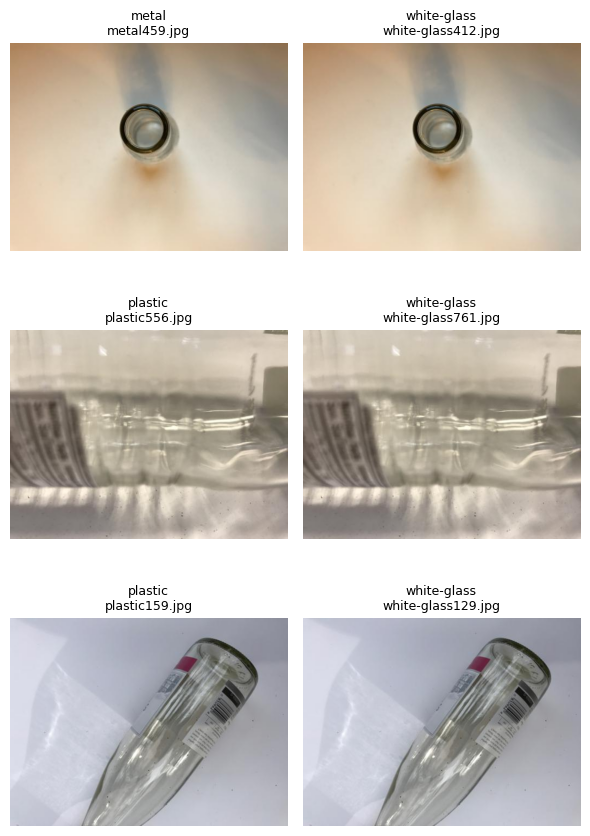

In [10]:
# 각 중복 그룹 안에 클래스가 몇 종류인지 계산 → 2 이상이면 '서로 다른 클래스끼리 중복'
n_labels = dup.groupby('md5')['label'].transform('nunique')
cross = dup[n_labels > 1].copy()
cross['file'] = cross['path'].apply(os.path.basename)   # 경로에서 파일 이름만 꺼냄
print(cross[['md5', 'label', 'file']].to_string(index=False))

# 그룹마다 한 행씩, 같은 사진이 어떤 클래스 이름으로 들어가 있는지 나란히 그림
groups = cross['md5'].unique()
size = cross.groupby('md5').size().max()    # 그룹 안 사진 수의 최댓값 = 열 개수
fig, axes = plt.subplots(len(groups), size, figsize=(3 * size, 3 * len(groups)), squeeze=False)

for i, h in enumerate(groups):
    rows = cross[cross['md5'] == h]
    for j, (p, label) in enumerate(zip(rows['path'], rows['label'])):
        axes[i, j].imshow(Image.open(p).convert('RGB'))
        axes[i, j].set_title(f'{label}\n{os.path.basename(p)}', fontsize=9)

for ax in axes.flat:
    ax.axis('off')
plt.tight_layout()
plt.show()


**관찰**
- 3그룹 모두 한쪽이 white-glass이고 상대는 metal 1그룹, plastic 2그룹임
- metal / white-glass 그룹은 사진상 유리병이라 metal 라벨이 틀린 것으로 보임
- plastic / white-glass 2그룹은 사진만으로 재질을 확정하기 어려움
- 세 그룹 모두 같은 연한 배경의 실제 촬영 사진임 → metal, plastic, white-glass 일부가 같은 출처에서 왔음

**시사점**
- white-glass ↔ plastic 혼동이 **데이터 라벨 자체에도** 있음 → 오류 분석에서 이 쌍을 해석할 근거가 됨
- 정답이 모호하므로 서로 다른 클래스끼리 겹친 6장은 **모두 제거**함 ("모호한 라벨은 제거"라는 하나의 규칙)

### 1-8. 극단적인 가로/세로 비율 확인

극단 비율 이미지: 249 장 (1.6%)
             count  class_ratio(%)
label                             
battery         35             3.7
clothes         35             0.7
green-glass     30             4.8
biological      30             3.0
paper           29             2.8
shoes           24             1.2
trash           21             3.0
cardboard       12             1.3
white-glass     10             1.3
brown-glass      9             1.5
plastic          8             0.9
metal            6             0.8


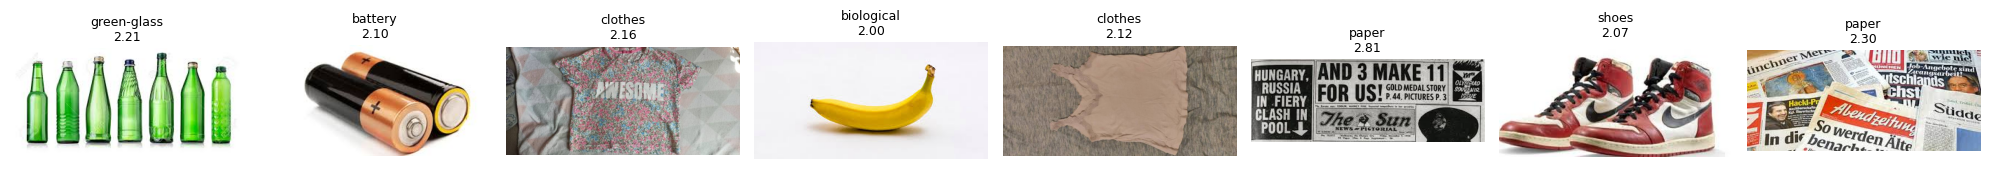

In [11]:
# 가로/세로 비율이 2 이상(아주 넓은 사진) 또는 0.5 이하(아주 긴 사진)인 이미지
extreme = df[(df['aspect'] >= 2) | (df['aspect'] <= 0.5)]
print('극단 비율 이미지:', len(extreme), '장', f'({len(extreme) / len(df) * 100:.1f}%)')

# 클래스별 장수와, 그 클래스 전체에서 차지하는 비율(%)
summary = pd.DataFrame({
    'count': extreme['label'].value_counts(),
    'class_ratio(%)': (extreme['label'].value_counts() / df['label'].value_counts() * 100).round(1),
}).fillna(0).sort_values('count', ascending=False)
print(summary)

# 극단 비율 이미지 예시 8장 (제목: 클래스, 비율)
show = extreme.sample(min(8, len(extreme)), random_state=42)
fig, axes = plt.subplots(1, len(show), figsize=(2.5 * len(show), 3), squeeze=False)
for ax, p, label, a in zip(axes[0], show['path'], show['label'], show['aspect']):
    ax.imshow(Image.open(p).convert('RGB'))
    ax.set_title(f'{label}\n{a:.2f}', fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()


**관찰**
- 극단 비율 이미지는 249장(1.6%)이고, 클래스별로 많아야 green-glass 4.8%, battery 3.7%임 (10%를 넘는 클래스 없음)
- 대부분 병을 일렬로 놓은 사진, 신문 지면, 신발 한 켤레처럼 원래 가로로 긴 장면임

**시사점**
- 정사각형 **단순 resize**로 결정함 (찌그러짐은 1.6%에만 생기고 특정 클래스에 몰리지 않음)
- 가운데 잘라내기(center crop)는 쓰지 않음 → 일렬로 놓인 물체의 일부가 잘려 나감

### 1단계 결론 (2단계로 넘기는 결정 사항)

| 결정 | 근거 |
|---|---|
| 주지표 macro-F1, accuracy는 참고 | 1-2: 상위 2개 클래스가 47%, 불균형 8.8배 |
| 층화 분할 | 1-2 |
| 다른 클래스끼리 겹친 6장 모두 제거, 같은 클래스 중복은 1장만 남김 (분할 전) | 1-6, 1-7 |
| RGB 변환 후 정사각형 단순 resize | 1-4, 1-8 |
| 색조·흑백 증강 금지 / 반전·회전·자르기·밝기 증강은 후보 | 1-3, 1-5 |
| 오류 분석 대상: white-glass ↔ plastic, paper ↔ cardboard, 유리 3종 | 1-3, 1-5, 1-7 |
| 한계: 클래스마다 출처·배경이 달라 지름길 학습 위험, 상품 사진 위주, 일부 라벨 오류 | 1-3, 1-7 |

# Data

### 2-1. 데이터 정제
데이터 정제: train/val/test로 나누기 전에 중복 이미지를 정리하는 코드임
- 1-6 결과: 내용이 완전히 같은 파일(md5가 같은 파일)이 18그룹 37장 있었음
- 1-7 결과: 그중 3그룹(6장)은 서로 다른 클래스에 들어 있었음 → 정답이 모호함
- 분할 전에 정리하지 않으면 같은 사진이 train과 test에 동시에 들어가서
- 시험 문제를 미리 본 것처럼 점수가 부풀려질 수 있음


In [12]:
# 각 행이 속한 md5 그룹 안에 클래스가 몇 종류 있는지 계산함
#  - 중복이 아닌 이미지는 그룹에 자기 하나뿐이라 1이 나옴
#  - 같은 클래스끼리 중복이면 1이 나옴
#  - 서로 다른 클래스끼리 중복이면 2 이상이 나옴
n_labels = df.groupby('md5')['label'].transform('nunique')

# (1) 서로 다른 클래스끼리 겹친 이미지는 어느 라벨이 맞는지 확정할 수 없으므로 전부 제거함
# → n_labels가 1인 행만 남김
clean = df[n_labels == 1]

# (2) 같은 클래스 안에서 중복된 이미지는 처음 나온 1장만 남기고 나머지를 제거함
# reset_index는 행 번호를 0부터 다시 매기는 것임 (중간에 빠진 번호가 없게)
clean = clean.drop_duplicates('md5', keep='first').reset_index(drop=True)

print('정제 전:', len(df), '장')
print('정제 후:', len(clean), '장')
print('제거됨 :', len(df) - len(clean), '장')


정제 전: 15515 장
정제 후: 15493 장
제거됨 : 22 장


In [13]:
# 정제가 의도대로 됐는지 확인하는 코드임

# 남은 데이터에 같은 md5가 또 있는지 확인함 → 0이어야 정상임
print('남은 중복 수:', clean['md5'].duplicated().sum())

# 클래스별로 정제 전과 후의 장수를 나란히 비교함
# 어느 클래스에서 몇 장이 빠졌는지 보고서에 그대로 쓸 수 있는 표임
compare = pd.DataFrame({
    'before': df['label'].value_counts(),      # 정제 전 클래스별 장수
    'after': clean['label'].value_counts(),    # 정제 후 클래스별 장수
})
compare['removed'] = compare['before'] - compare['after']   # 클래스별로 제거된 장수
print(compare.sort_values('removed', ascending=False))
print('클래스 수:', clean['label'].nunique())   # 12가 그대로 유지돼야 함


남은 중복 수: 0
             before  after  removed
label                              
green-glass     629    614       15
white-glass     775    772        3
plastic         865    863        2
clothes        5325   5324        1
metal           769    768        1
biological      985    985        0
shoes          1977   1977        0
paper          1050   1050        0
battery         945    945        0
cardboard       891    891        0
trash           697    697        0
brown-glass     607    607        0
클래스 수: 12


**결과**
- 15,515장 → **15,493장** (22장 제거), 남은 중복 0, 클래스 수 12 유지
- 가장 많이 빠진 클래스는 green-glass(15장)임
- 가장 적은 클래스는 여전히 brown-glass(607장)라 불균형 정도는 거의 그대로임

### 2-2. 데이터 분할
- train / val / test = 70 / 15 / 15
- 층화 분할
- SEED 12345

In [14]:
from sklearn.model_selection import train_test_split

# train: 모델 학습에 쓰는 데이터임
# val  : 조기 종료, 하이퍼파라미터 선택, 모델 비교에 쓰는 데이터임
# test : 최종 모델 1개를 마지막에 딱 한 번만 평가하는 데이터임 (그 전에는 절대 안 봄)
# stratify = 라벨 : 층화 분할 옵션임. 각 세트의 클래스 비율이 전체 비율과 같아지게 나눔
# → 불균형이 심해서(최대/최소 8.8배) 이걸 안 하면 소수 클래스가 한쪽에 몰릴 수 있음
# random_state = 12345 : 시드 고정임. 런타임이 끊겨서 다시 실행해도 똑같이 나뉨
#  → 단, 같은 환경일 때만 같음: Colab과 내 PC는 1-1에서 파일을 읽는 순서가 달라서 분할이 달라짐 (아래 분할 지문 참고)

# 먼저 전체에서 test 15%를 떼어냄 → 남은 85%는 train_val
train_val, test = train_test_split(
    clean,
    test_size = 0.15,
    stratify = clean['label'],
    random_state = 12345)

# 남은 85%에서 val을 떼어냄
# val이 '전체'의 15%가 되려면 남은 85% 중에서 0.15 / 0.85 ≈ 17.6%를 떼어야 함
train, val = train_test_split(
    train_val,
    test_size = 0.15 / 0.85,
    stratify = train_val['label'],
    random_state = 12345)

print('train:', len(train), '장')
print('val  :', len(val), '장')
print('test :', len(test), '장')
print('합계 :', len(train) + len(val) + len(test), '장  (정제 후 전체와 같아야 함)')

# 분할 지문(split_id)을 만들고, 저장 폴더를 분할마다 따로 쓰는 코드임
#  - 지문 = val·test에 들어간 사진 파일 이름들로 만든 짧은 코드 → 분할이 같으면 항상 같은 값, 다르면 다른 값이 나옴
#  - 왜 필요한가: Colab과 내 PC는 파일을 읽는 순서가 달라서, 같은 random_state로 나눠도 분할이 달라짐
#    → 다른 분할에서 만든 저장 파일(전처리 이미지, 학습 결과)을 불러오면
#      test 사진으로 학습한 모델을 test로 평가하는 셈이 됨 (데이터 누수 → 점수가 부풀려짐)
#    → 저장 파일을 SAVE_DIR/split_지문 폴더에 두면, 분할이 다를 때는 자동으로 다른 폴더를 써서 섞이지 않음
#  - 예전 방식(SAVE_DIR 바로 아래)으로 저장된 .pt 파일은 이 분할 폴더로 옮김
#    → 같은 환경(같은 Drive 또는 같은 PC)에서 만든 파일이라 지금 분할과 같음 → 다시 학습하지 않고 그대로 씀
#  - 2-3(전처리 이미지)과 3-4(학습 결과)는 모두 CACHE_DIR에 저장하고 CACHE_DIR에서 불러옴
import hashlib, shutil

split_names = sorted(val['path'].map(os.path.basename)) + ['|'] + sorted(test['path'].map(os.path.basename))
split_id = hashlib.md5(''.join(split_names).encode()).hexdigest()[:8]     # 8글자 지문
CACHE_DIR = os.path.join(SAVE_DIR, f'split_{split_id}')
os.makedirs(CACHE_DIR, exist_ok = True)

for f in os.listdir(SAVE_DIR) :                                          # 예전 위치의 저장 파일을 분할 폴더로 옮김
    if f.endswith('.pt') :
        shutil.move(os.path.join(SAVE_DIR, f), os.path.join(CACHE_DIR, f))
        print('예전 위치의 저장 파일을 옮김 →', f)

print('분할 지문:', split_id, '| 저장 폴더:', CACHE_DIR)
print('저장된 파일:', sorted(os.listdir(CACHE_DIR)))

train: 10845 장
val  : 2324 장
test : 2324 장
합계 : 15493 장  (정제 후 전체와 같아야 함)
분할 지문: af2de917 | 저장 폴더: cache/split_af2de917
저장된 파일: []


In [15]:
# 분할이 의도대로 됐는지 두 가지를 확인하는 코드임

# 클래스별 장수와 비율 확인
# 층화 분할이 잘 됐다면 세 세트의 클래스 비율(%)이 거의 같아야 함
counts = pd.DataFrame({
    'train': train['label'].value_counts(),
    'val': val['label'].value_counts(),
    'test': test['label'].value_counts(),
})
ratios = (counts / counts.sum() * 100).round(1)   # 세트마다 클래스 비율(%)을 계산함
print('[클래스별 장수]')
print(counts.sort_values('train', ascending=False))
print('\n[클래스별 비율(%)] — 세 열이 비슷하면 층화 분할 성공임')
print(ratios.sort_values('train', ascending=False))

# (2) 누수 확인: 같은 이미지(md5)가 두 세트에 동시에 들어 있는지 확인함
#     2-1에서 중복을 정리했으므로 세 값 모두 0이어야 정상임
print('\ntrain ∩ val :', len(set(train['md5']) & set(val['md5'])))
print('train ∩ test:', len(set(train['md5']) & set(test['md5'])))
print('val ∩ test  :', len(set(val['md5']) & set(test['md5'])))


[클래스별 장수]
             train  val  test
label                        
clothes       3727  798   799
shoes         1384  296   297
paper          735  158   157
biological     689  148   148
battery        661  142   142
cardboard      623  134   134
plastic        605  129   129
white-glass    540  116   116
metal          538  115   115
trash          488  105   104
green-glass    430   92    92
brown-glass    425   91    91

[클래스별 비율(%)] — 세 열이 비슷하면 층화 분할 성공임
             train   val  test
label                         
clothes       34.4  34.3  34.4
shoes         12.8  12.7  12.8
paper          6.8   6.8   6.8
biological     6.4   6.4   6.4
battery        6.1   6.1   6.1
cardboard      5.7   5.8   5.8
plastic        5.6   5.6   5.6
white-glass    5.0   5.0   5.0
metal          5.0   4.9   4.9
trash          4.5   4.5   4.5
green-glass    4.0   4.0   4.0
brown-glass    3.9   3.9   3.9

train ∩ val : 0
train ∩ test: 0
val ∩ test  : 0


**결과**
- train 10,845 / val 2,324 / test 2,324장 (합계 15,493장)
- 세 세트의 클래스 비율 차이가 최대 0.1%p → 층화 분할이 잘 됨
- 가장 적은 brown-glass도 val/test에 각각 91장씩 들어감
- 세 세트 사이에 같은 이미지(md5)가 0장 → 누수 없음

### 2-3. 데이터 전처리

In [16]:
import numpy as np
import torch

# 모든 이미지를 RGB 128x128로 바꿔서 메모리에 올려 두는 코드임
# 학습할 때마다 jpg 파일을 다시 읽으면 매 epoch마다 느려짐
# → 여기서 한 번만 읽고 숫자 배열(텐서)로 저장해 두고 계속 재사용함

#  - convert('RGB') : 1-4에서 P(팔레트) 모드 34장을 확인했음 → 전부 3채널 컬러로 통일함
#  - resize((128, 128)) : 1-8에서 극단 비율이 1.6%뿐이라 정사각형 단순 resize로 정했음
#  - uint8(0~255 정수)로 저장함 → 소수(float)로 저장하는 것보다 메모리를 1/4만 씀
#  - 15,493장을 읽으므로 1~3분 정도 걸림
#  - 저장: 처음 한 번만 이미지를 읽고 결과를 CACHE_DIR(2-2의 분할 폴더)에 파일로 저장함
#    → 다음부터는 파일이 있으면 이미지를 다시 읽지 않고 바로 불러옴
#    → 파일 이름에 크기를 넣어서 이미지 크기 실험(64/256px)의 결과와 섞이지 않게 함
#    → 분할이 바뀌면 2-2의 분할 지문이 달라져 다른 폴더를 쓰므로, 예전 분할의 파일을 잘못 불러오지 않음

IMG_SIZE = 128
cache = os.path.join(CACHE_DIR, f'images_{IMG_SIZE}px.pt')   # 저장 파일 경로

if os.path.exists(cache) :
    images = torch.load(cache)                    # 저장된 이미지 텐서를 그대로 불러옴
    print('저장된 전처리 결과를 불러옴 ←', cache)
else :
    images = {}   # 세트 이름 → 이미지 텐서를 담을 딕셔너리임
    for name, data in [('train', train), ('val', val), ('test', test)] :
        # 이미지 수 x 채널(3) x 세로 x 가로 크기의 빈 텐서를 먼저 만들어 둠
        #  PyTorch는 채널을 맨 앞에 두는 (C, H, W) 순서를 씀
        x = torch.empty(len(data), 3, IMG_SIZE, IMG_SIZE, dtype = torch.uint8)

        for i, p in enumerate(data['path']) :
            img = Image.open(p).convert('RGB').resize((IMG_SIZE, IMG_SIZE))     # RGB 변환 + 크기 통일
            arr = np.array(img)                                                 # (H, W, C) 모양의 숫자 배열이 됨
            x[i] = torch.from_numpy(arr).permute(2, 0, 1)                       # (C, H, W)로 축 순서를 바꿔 저장함

        images[name] = x
    torch.save(images, cache)                     # 다음 실행 때 바로 불러올 수 있게 파일로 저장함
    print('전처리 결과를 저장함 →', cache)

for name in images :
    print(name, tuple(images[name].shape))

# 정답 라벨 : 클래스 이름을 0~11 정수로 바꿈
#  - CrossEntropyLoss는 정답을 정수 번호로 받음
#  - CLASSES는 알파벳순이라 번호가 항상 같게 매겨짐 (battery=0, ..., white-glass=11)
class_to_idx = {c: i for i, c in enumerate(CLASSES)}
labels = {name: torch.tensor(data['label'].map(class_to_idx).values)
          for name, data in [('train', train), ('val', val), ('test', test)]}
print(class_to_idx)

# 저장 파일과 지금 분할의 장수가 같은지 확인함 → 다르면 저장 파일이 예전 분할로 만든 것임
for name in images :
    assert len(images[name]) == len(labels[name]), f'{name} 장수가 다름 → {cache} 파일을 지우고 다시 실행할 것'

전처리 결과를 저장함 → cache/split_af2de917/images_128px.pt
train (10845, 3, 128, 128)
val (2324, 3, 128, 128)
test (2324, 3, 128, 128)
{'battery': 0, 'biological': 1, 'brown-glass': 2, 'cardboard': 3, 'clothes': 4, 'green-glass': 5, 'metal': 6, 'paper': 7, 'plastic': 8, 'shoes': 9, 'trash': 10, 'white-glass': 11}


In [17]:
# 정규화에 쓸 평균과 표준편차를 계산하는 코드임
#  - 정규화 : (픽셀값 - 평균) / 표준편차 → 값의 범위를 평균 0, 표준편차 1 근처로 맞춤
#  - 기준은 반드시 train 데이터로만 계산함
#  → val/test 통계를 쓰면 시험 데이터를 미리 본 셈이 됨 (강의 3주차 원칙)
#  - train 전체(10,845장)를 한꺼번에 소수로 바꾸면 메모리를 약 2GB 써서
#  무작위 2,000장만 뽑아 계산함 (평균·표준편차 추정에는 충분한 양임)
#  - R, G, B 채널마다 따로 계산해서 값이 3개씩 나옴

torch.manual_seed(12345)                                      # 뽑는 2,000장을 매번 같게 고정함
idx = torch.randperm(len(images['train']))[:2000]             # train에서 무작위 2,000장 번호를 뽑음
sample_x = images['train'][idx].float() / 255                 # 0~255 → 0~1 범위의 소수로 바꿈

MEAN = sample_x.mean(dim = (0, 2, 3)).tolist()   # (이미지, 세로, 가로) 방향으로 평균 → 채널별 값 3개가 남음
STD = sample_x.std(dim = (0, 2, 3)).tolist()     # 같은 방향으로 표준편차
print('MEAN (R, G, B):', [round(m, 3) for m in MEAN])
print('STD  (R, G, B):', [round(s, 3) for s in STD])


MEAN (R, G, B): [0.658, 0.615, 0.583]
STD  (R, G, B): [0.279, 0.29, 0.304]


train 0.50 GB | 라벨 수: 10845
val 0.11 GB | 라벨 수: 2324
test 0.11 GB | 라벨 수: 2324


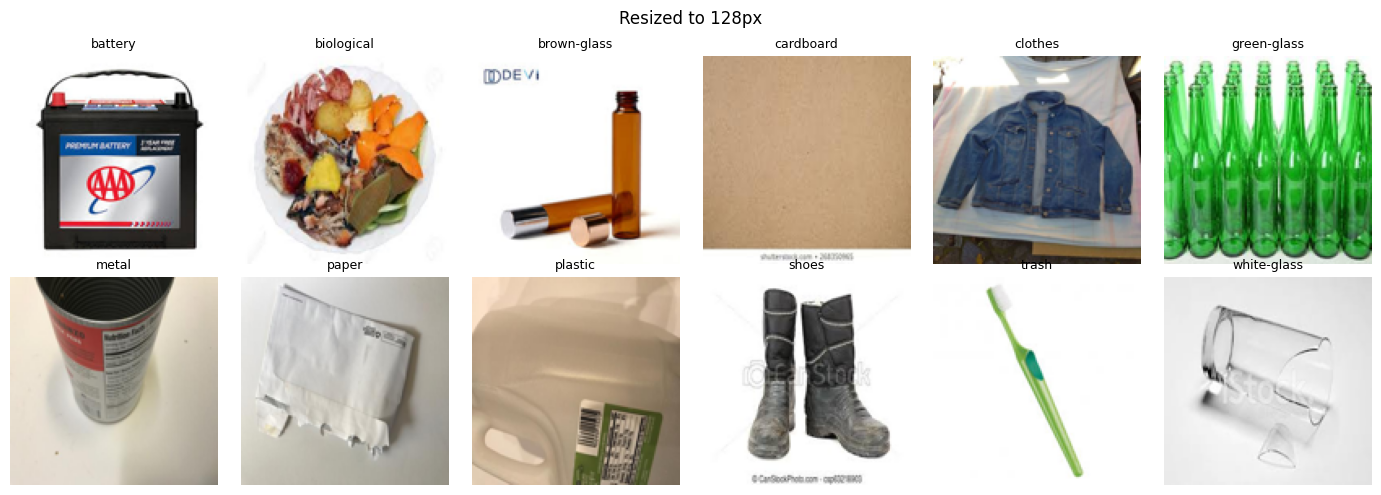

In [18]:
# 전처리가 의도대로 됐는지 확인하는 코드임

# 메모리 사용량 확인: 장수 x 3 x 128 x 128 바이트(uint8은 1칸에 1바이트)
for name in ['train', 'val', 'test'] :
    print(name, f"{images[name].numel() / 1024**3:.2f} GB", '| 라벨 수:', len(labels[name]))

# 128px로 줄인 이미지가 알아볼 만한지 클래스별 1장씩 확인함
# 특히 white-glass, plastic, paper, cardboard의 질감이 남아 있는지 눈으로 봄
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ax, c in zip(axes.flat, CLASSES):
    i = (labels['train'] == class_to_idx[c]).nonzero()[0].item()   # 해당 클래스의 첫 번째 train 이미지 번호
    ax.imshow(images['train'][i].permute(1, 2, 0))                   # (C, H, W) → (H, W, C)로 바꿔야 그림이 그려짐
    ax.set_title(c, fontsize=9)
    ax.axis('off')
plt.suptitle(f'Resized to {IMG_SIZE}px')
plt.tight_layout()
plt.show()


**결과**
- 텐서 모양: train (10845, 3, 128, 128), val·test (2324, 3, 128, 128) / 메모리 합계 약 0.72GB
- 정규화 기준값(train 2,000장 표본, SEED 12345): MEAN (R, G, B) = 0.658 / 0.615 / 0.583, STD = 0.279 / 0.290 / 0.304
  - 흰 배경 사진이 많아 전체적으로 밝은 쪽임

**관찰 (128px 샘플)**
- 12클래스 모두 물체를 알아볼 수 있음
- **워터마크·스톡사진 표시가 128px에서도 남아 있음**: brown-glass(DEVI 로고), cardboard(shutterstock), shoes(CanStock), white-glass(iStock)
  → 출처 차이가 리사이즈 후에도 그대로 남음 → 모델이 워터마크를 단서로 쓸 위험이 있음 (오류 분석에서 확인)
- metal, paper, plastic 샘플이 모두 같은 베이지 배경의 실제 촬영 사진임
  → 이 세 클래스끼리는 배경으로 구분할 수 없어서 물체 자체(재질·모양)로 구분해야 함
- cardboard 샘플은 물체 없이 골판지 표면만 찍힌 사진임 → 이 클래스는 질감이 핵심 단서임
- white-glass는 투명해서 윤곽선만 보임 → 작은 크기에서 더 어려워질 수 있음
- (분할을 다시 하기 전 샘플에서는 초록색 플라스틱 병도 보였음 → green-glass ↔ plastic 혼동도 오류 분석 후보임)

**시사점**
- 128px가 충분한지는 하이퍼파라미터 실험에서 64 / 128 / 256을 비교해 숫자로 확인함 (질감이 중요한 cardboard·white-glass를 특히 봄)

### 2-4. 데이터 증강

In [19]:
from torchvision.transforms import v2 as T

# 데이터 증강(augmentation)과 정규화를 정의하는 코드임
#  - 증강: 학습 이미지를 매번 조금씩 바꿔서 같은 데이터를 여러 장처럼 쓰는 방법임 (강의 9주차)
#  - 증강은 train에만 적용함. val/test까지 바꾸면 평가할 때마다 점수가 달라져 비교가 안 됨
#  - 2단계 설계에 따라 증강 강도를 3단계(none / weak / strong)로 만들어 두고 실험에서 비교함
#  - 3-7(Optuna)을 위해 자동 증강 trivial과 RandomErasing(사진 일부 지우기)을 추가함

# 정규화 : 모든 세트에 공통으로 마지막에 적용함
# ToDtype(scale=True) : uint8(0~255) → float(0~1)로 바꿈
# Normalize(MEAN, STD): 2-3에서 train으로 계산한 값으로 (값 - 평균) / 표준편차를 계산함
normalize = [T.ToDtype(torch.float32, scale=True), T.Normalize(MEAN, STD)]

# 약한 증강 : 좌우, 상하 반전만 사용함
# 쓰레기는 정해진 방향이 없어서 뒤집어도 같은 클래스임 (숫자 MNIST와 다른 점)
aug_weak = [
    T.RandomHorizontalFlip(),   # 50% 확률로 좌우 반전함
    T.RandomVerticalFlip(),     # 50% 확률로 상하 반전함
]

# 강한 증강 : 반전 + 무작위 자르기, 확대 + 회전 + 밝기, 대비
# RandomResizedCrop : 원본의 70~100% 영역을 무작위로 잘라 다시 128px로 키움
# → 물체 위치·크기를 다양하게 해서 배경에 덜 의존하게 함 (1-3)
# RandomRotation(30): -30도~+30도 사이로 무작위 회전함 (빈 모서리는 검은색으로 채워짐)
# ColorJitter       : 밝기·대비만 ±20% 바꿈 → 클래스마다 다른 배경 밝기에 덜 의존하게 함 (1-5)
# hue(색조)와 흑백 변환은 일부러 넣지 않았음 → 유리 3종은 색 자체가 정답이기 때문임 (1-5)
aug_strong = [
    T.RandomResizedCrop(IMG_SIZE, scale = (0.7, 1.0), antialias = True),
    T.RandomHorizontalFlip(),
    T.RandomVerticalFlip(),
    T.RandomRotation(30),
    T.ColorJitter(brightness = 0.2, contrast = 0.2),
]

# TrivialAugment(색 변환 제외) : 사진마다 변환 하나를 무작위로 고르고, 세기도 무작위로 정해 적용함
#  - 사람이 증강 조합을 정하지 않아도 되는 자동 증강 방법임 (TrivialAugmentWide, torchvision 제공)
#  - 원래 14가지 변환 중 색을 바꾸는 5가지(Color·Posterize·Solarize·AutoContrast·Equalize)는 뺌
#    → 유리 3종은 색 자체가 정답이라, 색을 바꾸면 라벨과 안 맞는 사진이 됨 (1-5, hue를 뺀 것과 같은 이유)
#  - 남은 9가지: 그대로 두기, 가로·세로 기울이기, 가로·세로 이동, 회전, 밝기, 대비, 선명도
#  - 방법: TrivialAugmentWide를 물려받고, 고를 수 있는 변환 목록(_AUGMENTATION_SPACE)만 KEEP으로 줄임
KEEP = ['Identity', 'ShearX', 'ShearY', 'TranslateX', 'TranslateY', 'Rotate', 'Brightness', 'Contrast', 'Sharpness']

class TrivialAugmentNoColor(T.TrivialAugmentWide) :
    _AUGMENTATION_SPACE = {k: v for k, v in T.TrivialAugmentWide._AUGMENTATION_SPACE.items() if k in KEEP}

aug_trivial = [TrivialAugmentNoColor()]

# RandomErasing : 50% 확률로 사진의 일부(넓이 2~20%)를 사각형으로 지움
#  - 한 부분(배경·워터마크·물체 일부)만 보고 맞히지 못하게 해서, 사진 전체를 보고 판단하게 만듦 (1-3의 지름길 학습 대응)
#  - 정규화 뒤에 덧붙여 씀(2-5의 make_train_loader) → 지운 곳의 값 0 = 평균 색
random_erase = T.RandomErasing(p = 0.5, scale = (0.02, 0.2), value = 0)

# 최종 변환 묶음 : 증강 + 정규화 순서로 이어 붙임
TRANSFORMS = {
    'none': T.Compose(normalize),                 # 증강 없음 (정규화만)
    'weak': T.Compose(aug_weak + normalize),
    'strong': T.Compose(aug_strong + normalize),
    'trivial': T.Compose(aug_trivial + normalize),   # 자동 증강 (색 변환 제외)
}
eval_tf = T.Compose(normalize)   # val/test용: 증강 없이 정규화만 함

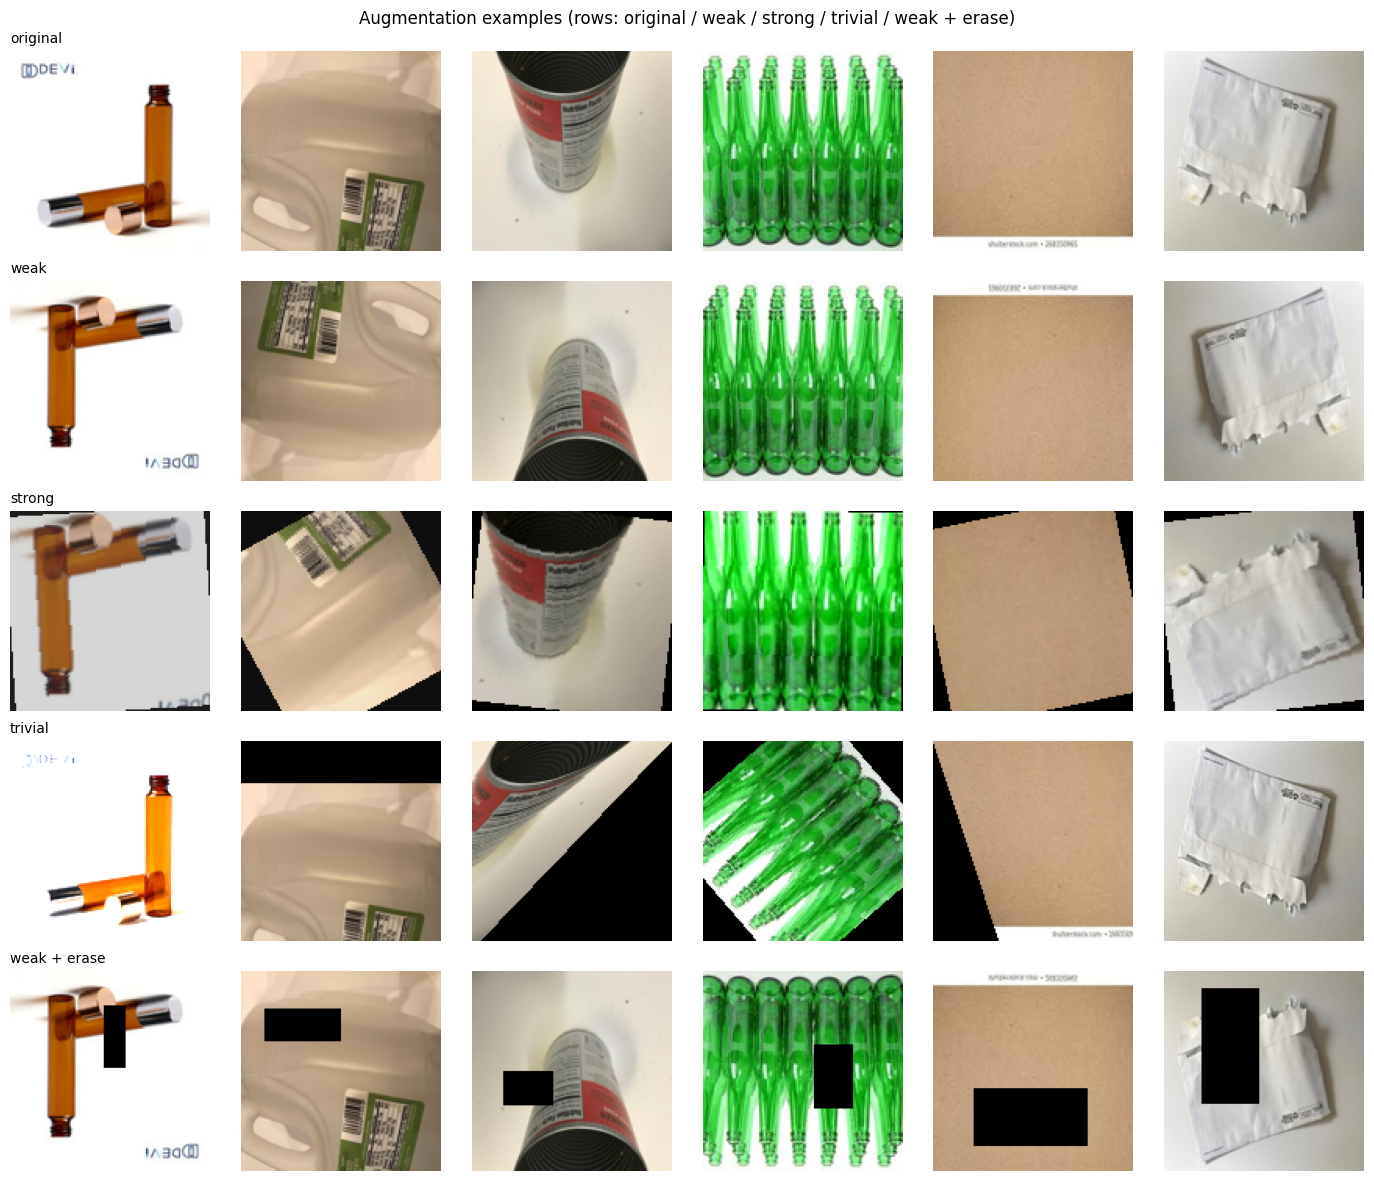

In [20]:
# 증강이 의도대로 적용되는지 그림으로 확인하는 코드임
#  - 정규화까지 하면 색이 이상하게 보여서, 여기서는 증강만 적용해서 그림
#  - 행: 원본(128px) / weak / strong / trivial(색 변환 제외) / weak + 지우기(RandomErasing)
#    → 지우기는 그림에서 잘 보이도록 항상(100%) 적용함 (학습 때는 50%)
#  - 같은 이미지라도 실행할 때마다 증강 결과가 달라짐 (무작위이기 때문임)

examples = [('original', T.Identity()),
            ('weak', T.Compose(aug_weak)),
            ('strong', T.Compose(aug_strong)),
            ('trivial', T.Compose(aug_trivial)),
            ('weak + erase', T.Compose(aug_weak + [T.RandomErasing(p = 1.0, scale = (0.02, 0.2), value = 0)]))]

fig, axes = plt.subplots(len(examples), 6, figsize = (14, 2.4 * len(examples)))
for r, (title, tf) in enumerate(examples) :
    for j in range(6) :                                           # train 앞쪽 6장을 사용함
        axes[r, j].imshow(tf(images['train'][j]).permute(1, 2, 0))
        axes[r, j].axis('off')
    axes[r, 0].set_title(title, loc = 'left', fontsize = 10)      # 각 행 첫 칸에 증강 이름
plt.suptitle('Augmentation examples (rows: original / weak / strong / trivial / weak + erase)')
plt.tight_layout()
plt.show()

**관찰**
- weak: 좌우·상하 반전이 의도대로 적용됨 (DEVI 로고, shutterstock 글자가 뒤집힘)
  - 반전은 각각 50% 확률이라 plastic처럼 아무것도 안 뒤집힌 경우도 있음 (정상)
- strong: 회전, 잘라서 확대, 밝기·대비 변화가 모두 적용됨
- **색조는 바뀌지 않음** (갈색 병은 갈색, 초록 병은 초록색 그대로) → 설계대로임
- strong에서 회전 때문에 생긴 검은 모서리가 크고, 자르기와 회전이 겹치면 물체 일부만 남는 경우가 있음
- 밝기·대비 변화로 흰 배경이 회색으로 바뀜 (brown-glass) → 배경 밝기 지름길을 줄이는 의도대로 작동함

**시사점**
- strong이 과하면 성능이 오히려 떨어질 수 있음 → 증강 강도 비교(none / weak / strong) 실험으로 확인함
- strong이 weak보다 나쁘면 회전 각도를 15°로 줄이거나 빈 모서리를 흰색으로 채우는 것을 다음 후보로 시험함

### 2-5. Dataset · DataLoader

In [21]:
from torch.utils.data import Dataset, DataLoader

# 사용자 정의 Dataset을 만드는 코드임
#  - Dataset은 "i번째 데이터 1개를 꺼내는 방법"을 정해 두는 클래스임
#  - DataLoader가 이 클래스를 반복 호출해서 batch(묶음)를 만듦
#  - 이미지는 2-3에서 이미 메모리에 올려 뒀으므로 여기서는 꺼내서 변환만 함

class GarbageDataset(Dataset) :
    def __init__(self, x, y, transform) :
        # 객체를 만들 때 한 번만 실행됨: 이미지 텐서, 라벨 텐서, 적용할 변환을 저장해 둠
        self.x = x
        self.y = y
        self.transform = transform

    def __len__(self):
        # 전체 데이터 개수를 알려줌 → len(dataset)으로 호출됨
        return len(self.y)

    def __getitem__(self, i) :
        # i번째 이미지에 변환(증강+정규화)을 적용하고 정답 라벨과 짝으로 돌려줌
        # 변환이 매번 새로 무작위로 적용되므로 epoch마다 조금씩 다른 이미지가 됨
        return self.transform(self.x[i]), self.y[i]


In [22]:
# 기준 설정으로 DataLoader를 만들고 batch 하나를 꺼내서 확인하는 코드임
#  - 첫 실험(기준 모델)은 증강 없이 하므로 train도 'none'을 씀
#  - 증강·batch 크기 실험에서는 make_train_loader로 train DataLoader만 새로 만듦

from torch.utils.data import WeightedRandomSampler

BATCH_SIZE = 64   # 2단계 고정 조건임

# 데이터를 준비하는 보조 프로세스 수임
#  - Colab(리눅스): 2개를 써서 GPU가 데이터를 기다리는 시간을 줄임
#  - 내 PC(Windows): 0개 (보조 프로세스 없이 메인에서 준비함)
#    → Windows의 Jupyter에서는 노트북 안에서 만든 클래스(GarbageDataset)를 보조 프로세스로 넘기지 못해 오류가 남
NUM_WORKERS = 0 if os.name == 'nt' else 2   # os.name == 'nt' 이면 Windows임

# train DataLoader를 만드는 함수임
#  - 증강(aug), 지우기(erase), 오버샘플링(oversample), batch 크기만 바꿔서 실험마다 train DataLoader를 새로 만들 때 씀
#  - erase = True : 2-4의 RandomErasing을 정규화 뒤에 덧붙임
#  - oversample = True : 불균형 처리 방법 중 하나 (3-7)
#    - 사진마다 뽑힐 확률을 '1 / 그 클래스 장수'로 줌 → 매 epoch 12개 클래스가 거의 같은 수로 뽑힘
#    - 적은 클래스(유리 약 430장)는 한 epoch에 여러 번, 많은 클래스(clothes 3,727장)는 일부만 뽑힘
#    - 뽑힐 때마다 증강이 달라서 같은 사진을 그대로 외우지는 않음 / 증강은 모든 클래스에 똑같이 적용함
#    - 한 epoch에 뽑는 수는 train 장수와 같게 둠 → epoch당 학습량은 다른 실험과 같음
#    - 이때는 shuffle 대신 sampler가 순서를 정함 (둘을 같이 쓸 수 없음)
#    (E3 증강 비교, E4 조합, batch 크기 비교) → 같은 DataLoader 코드를 실험마다 복사하지 않음
#  - 나머지 설정은 항상 같음 → 실험끼리 조건이 같게 유지됨
#    - shuffle = True  : train은 매 epoch마다 순서를 섞음 (클래스 순서대로 들어가면 학습이 한쪽으로 기움, 강의 5주차)
#    - drop_last = True: 마지막에 batch 크기가 안 되는 작은 묶음을 버림 (작은 batch는 BatchNorm을 불안정하게 함)
#    - num_workers = NUM_WORKERS : 데이터를 준비하는 보조 프로세스 수 (위 설명)
def make_train_loader(aug = 'none', batch_size = BATCH_SIZE, erase = False, oversample = False) :
    tf = TRANSFORMS[aug]
    if erase :
        tf = T.Compose([tf, random_erase])                         # 정규화 뒤에 지우기를 덧붙임
    ds = GarbageDataset(images['train'], labels['train'], tf)

    sampler = None
    if oversample :
        counts = torch.bincount(labels['train'])                   # 클래스별 장수
        weights = 1.0 / counts[labels['train']].double()           # 사진마다 '1 / 그 클래스 장수'
        sampler = WeightedRandomSampler(weights, num_samples = len(ds), replacement = True)

    return DataLoader(ds,
                      batch_size = batch_size,
                      shuffle = sampler is None,                    # sampler가 없을 때만 섞음 (기존과 같음)
                      sampler = sampler,
                      drop_last = True,
                      num_workers = NUM_WORKERS)

train_loader = make_train_loader('none')   # 기준 설정: 증강 없음, batch 64

# val/test: 증강 없이 정규화만 함(eval_tf), 섞을 이유가 없어서 shuffle = False
val_ds = GarbageDataset(images['val'], labels['val'], eval_tf)
test_ds = GarbageDataset(images['test'], labels['test'], eval_tf)

val_loader = DataLoader(val_ds,
                        batch_size = BATCH_SIZE,
                        shuffle = False,
                        num_workers = NUM_WORKERS)

test_loader = DataLoader(test_ds,
                         batch_size = BATCH_SIZE,
                         shuffle = False,
                         num_workers = NUM_WORKERS)

print('batch 수 → train:', len(train_loader), '| val:', len(val_loader), '| test:', len(test_loader))

# batch 하나를 꺼내서 모양과 값 범위를 확인함
xb, yb = next(iter(train_loader))
print('이미지 batch 모양:', tuple(xb.shape), xb.dtype)   # (64, 3, 128, 128), float32 이어야 함
print('라벨 batch 모양 :', tuple(yb.shape), yb.dtype)   # (64,), int64 이어야 함
print('라벨 예시       :', yb[:10].tolist())             # 섞여 있어야 함 (같은 숫자만 나오면 안 됨)

# 정규화가 잘 됐다면 채널별 평균은 0 근처, 표준편차는 1 근처가 나와야 함
print('채널별 평균     :', [round(v, 2) for v in xb.mean(dim=(0, 2, 3)).tolist()])
print('채널별 표준편차 :', [round(v, 2) for v in xb.std(dim=(0, 2, 3)).tolist()])

batch 수 → train: 169 | val: 37 | test: 37
이미지 batch 모양: (64, 3, 128, 128) torch.float32
라벨 batch 모양 : (64,) torch.int64
라벨 예시       : [9, 9, 0, 6, 4, 9, 10, 10, 2, 8]
채널별 평균     : [0.04, 0.07, 0.11]
채널별 표준편차 : [1.01, 1.03, 1.02]


**결과**
- batch 수: train 169 / val 37 / test 37 (train은 64장이 안 되는 마지막 묶음을 버림)
- 이미지 batch (64, 3, 128, 128) float32, 라벨 batch (64,) int64 → CrossEntropyLoss에 바로 넣을 수 있는 형태임
- 라벨 예시 6, 5, 4, 9, 4, 7, 7, 4, 1, 7 → 여러 클래스가 잘 섞여 있음 (4번 clothes가 자주 보이는 건 34% 비율 때문임)
- 채널별 평균 0.07 / 0.03 / 0.03, 표준편차 1.03 / 1.03 / 1.04 → 평균 0, 표준편차 1 근처라 정규화가 정상임
  - batch 하나(64장)만 본 값이라 정확히 0과 1이 아닌 건 자연스러움

### 2단계 결론 (데이터 준비 완료)

| 단계 | 결과 |
|---|---|
| 2-1 정제 | 15,515 → 15,493장 (중복·모호한 라벨 22장 제거) |
| 2-2 분할 | train 10,845 / val 2,324 / test 2,324, 층화 분할, 누수 0, SEED 12345 |
| 2-3 전처리 | RGB 변환 + 128px, 메모리 0.72GB, 정규화 기준값은 train으로만 계산 |
| 2-4 증강 | none / weak / strong 3단계, 색조 변경 없음 확인 |
| 2-5 Dataset · DataLoader | batch 64, 모양·값 범위 정상 |

- test 데이터(`test_loader`)는 최종 모델을 고르기 전까지 사용하지 않음

# Modeling

In [23]:
# 지금 연결된 Colab 서버에 GPU가 있는지 확인하는 코드임
#  - True면 GPU 사용 가능, False면 CPU 서버임 (런타임을 GPU로 다시 만들어야 함)
print('GPU 사용 가능:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU 이름:', torch.cuda.get_device_name(0))   # 보통 Tesla T4가 나옴

GPU 사용 가능: True
GPU 이름: NVIDIA L4


In [24]:
import random

# 시드를 고정하는 함수임 → 실험(학습)을 시작하기 직전마다 호출함
#  - 같은 시드로 시작해야 실험끼리 '같은 출발점'에서 비교할 수 있음 (강의 9주차 고정 조건)
#  - 시드가 영향을 주는 것: 모델 초기 가중치, train 데이터를 섞는 순서, 증강(회전 각도·자르는 위치 등)
#  - 셀이 아니라 함수로 만든 이유: 실험마다 학습 직전에 꼭 다시 고정해야 해서 한 줄로 부르기 위함임

SEED = 12345

def set_seed(seed=SEED) :
    random.seed(seed)                  # 파이썬 기본 난수 고정
    np.random.seed(seed)               # numpy 난수 고정
    torch.manual_seed(seed)            # PyTorch CPU 난수 고정 (초기 가중치, shuffle 순서, 증강)
    torch.cuda.manual_seed_all(seed)   # PyTorch GPU 난수 고정
    # GPU 연산 중 일부는 시드를 고정해도 실행할 때마다 미세하게 결과가 달라질 수 있음
    # 아래 두 줄은 GPU도 항상 같은 계산 방식을 쓰게 강제함 (대신 학습이 약간 느려질 수 있음)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)


device: cuda


In [25]:
import torch.nn as nn

# CNN 모델 구조를 정의하는 코드임 (구조 : Conv → ReLU → Pool → Flatten → Linear)
#  - 특징 추출부(features) : [Conv 3x3 → (BatchNorm) → ReLU → MaxPool] 블록을 4번 쌓음
#    - 채널(필터 수)은 3 → 32 → 64 → 128 → 256으로 늘어나고
#    - 크기는 MaxPool 때문에 블록마다 절반이 됨: 128 → 64 → 32 → 16 → 8
#  - 분류부(classifier) : 펼친 뒤(Flatten) Linear 2개로 12개 클래스 점수를 냄
#  - use_bn, dropout은 E1·E2 실험에서 켜기 위한 옵션임
#    - 기준 모델(E0)은 둘 다 끈 상태(use_bn = False, dropout = 0.0)로 씀
#    - Dropout(0.0)은 아무것도 안 하는 층이라 기준 모델에는 영향이 없음
#  - 마지막에 softmax를 넣지 않음 → CrossEntropyLoss가 내부에서 계산함 (강의 7주차)

class CNN(nn.Module) :
    def __init__(self, use_bn = False, dropout = 0.0, img_size = IMG_SIZE, n_classes = 12) :
        super().__init__()

        layers = []
        in_ch = 3                                   # 입력은 RGB 3채널임
        for out_ch in [32, 64, 128, 256] :
            layers.append(nn.Conv2d(in_ch, out_ch, kernel_size = 3, padding = 1))   # padding=1이면 크기가 유지됨
            if use_bn :
                layers.append(nn.BatchNorm2d(out_ch))   # Conv 다음, ReLU 앞에 둠 (강의 9주차)
            layers.append(nn.ReLU())
            layers.append(nn.MaxPool2d(2))              # 가로·세로를 절반으로 줄임
            in_ch = out_ch
        self.features = nn.Sequential(*layers)

        # 특징 맵 크기: 풀링 4번 → img_size / 16 (128px이면 8x8)
        # 펼친 길이 = 채널 256 x 8 x 8 = 16,384
        # img_size로 계산해 두면 이미지 크기 실험(64/256px)에서도 이 코드를 그대로 쓸 수 있음
        flat = 256 * (img_size // 16) ** 2

        self.classifier = nn.Sequential(
            nn.Flatten(),                 # (batch, 256, 8, 8) → (batch, 16384)
            nn.Dropout(dropout),
            nn.Linear(flat, 256),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(256, n_classes),    # 출력 = 클래스 12개의 점수
        )

    def forward(self, x) :
        return self.classifier(self.features(x))


In [26]:
# 모델에 가짜 이미지 1장을 넣어서 층마다 shape이 의도대로 바뀌는지 확인하는 코드임
#  - 강의 8주차 "막히면 shape을 찍는다"와 같은 방법임
#  - Flatten 크기를 잘못 계산하면 학습할 때 'shapes cannot be multiplied' 오류가 나는데, 이걸 미리 잡음

model = CNN()
x = torch.zeros(1, 3, IMG_SIZE, IMG_SIZE)          # (batch 1장, 채널 3, 128, 128)

print('입력:', tuple(x.shape))
for layer in model.features :                        # 특징 추출부를 한 층씩 통과시키며 출력 shape을 찍음
    x = layer(x)
    if isinstance(layer, nn.MaxPool2d) :             # 블록이 끝나는 MaxPool 뒤에서만 출력함
        print('블록 출력:', tuple(x.shape))
print('최종 출력:', tuple(model.classifier(x).shape))   # (1, 12)이어야 함

# 파라미터 수: 학습되는 숫자(가중치)가 몇 개인지 셈
n_feat = sum(p.numel() for p in model.features.parameters())
n_cls = sum(p.numel() for p in model.classifier.parameters())
print(f'파라미터 수 → 특징 추출부 {n_feat:,} / 분류부 {n_cls:,} / 전체 {n_feat + n_cls:,}')


입력: (1, 3, 128, 128)
블록 출력: (1, 32, 64, 64)
블록 출력: (1, 64, 32, 32)
블록 출력: (1, 128, 16, 16)
블록 출력: (1, 256, 8, 8)
최종 출력: (1, 12)
파라미터 수 → 특징 추출부 388,416 / 분류부 4,197,644 / 전체 4,586,060


In [27]:
import time, copy
from sklearn.metrics import f1_score

# 모델 하나를 학습하고 매 epoch의 학습·검증 결과를 기록하는 함수임
#  - 3단계의 모든 실험이 이 함수 하나로 학습함 → 실험마다 같은 코드를 복사하지 않음
#  - 한 epoch = (1) train 전체로 학습 + (2) val 전체로 검증
#  - 모든 실험을 50 epoch 학습함 (epochs 기본값)
#    → 30 epoch에서는 규제·증강을 넣은 조합의 최적 epoch이 마지막(30)에 걸리는 경우가 있었음 → 더 배울 여지를 줌
#  - 검증 macro-F1이 가장 높았던 epoch의 가중치를 따로 저장하고, 학습이 끝나면 그 가중치로 되돌림
#    → 검증 성능이 가장 좋았던 시점에서 멈춘 것과 같은 효과임
#  - test 데이터는 여기서 쓰지 않음 (최종 모델을 고른 뒤 마지막에 한 번만 씀)
#  - 저장: 학습이 끝나면 학습 기록과 최적 가중치를 CACHE_DIR/실험이름.pt 파일로 저장함 (CACHE_DIR = 2-2의 분할 폴더)
#    → 같은 이름의 파일이 이미 있으면 학습하지 않고 바로 불러옴 (런타임이 끊겨도 다시 학습할 필요 없음)
#    → 설정을 바꿔 다시 학습하려면 실험 이름(name)을 바꾸거나 저장 파일을 지워야 함
#  - class_weight: 불균형 처리용 클래스 가중치 (3-7) → 적은 클래스를 틀리면 손실(벌점)을 더 크게 줌
#    → val loss는 항상 가중치 없이 잼 → 실험끼리 같은 기준으로 비교할 수 있음
#  - on_epoch: epoch이 끝날 때마다 (epoch, val macro-F1)을 넘겨 부르는 함수 → Optuna가 가망 없는 시도를 중단시킬 때 씀 (3-7)
#  - verbose = False면 epoch별 기록을 출력하지 않고 마지막 한 줄만 출력함
#    → 3-7(Optuna)처럼 조합을 많이 학습할 때 출력이 너무 길어지지 않게 함

def train_model(model, train_loader, val_loader, name, epochs = 50, lr = 1e-3, verbose = True,
                class_weight = None, on_epoch = None) :
    model = model.to(device)                                    # 모델을 GPU로 옮김
    path = os.path.join(CACHE_DIR, f'{name}.pt')                # 실험 이름으로 저장 파일 경로를 만듦

    # (0) 저장된 결과가 있으면 학습을 건너뛰고 불러옴
    if os.path.exists(path) :
        ckpt = torch.load(path, map_location = device, weights_only = False)   # 직접 저장한 파일이라 그대로 불러와도 안전함
        model.load_state_dict(ckpt['state'])                    # 최적 시점의 가중치를 모델에 넣음 (test 평가·오류 분석에 씀)
        hist = pd.DataFrame(ckpt['history'])
        if verbose :
            print(hist.round(3).to_string(index = False))       # 저장된 epoch별 학습 기록을 표로 보여 줌
        print(f"최적 epoch: {ckpt['best_epoch']} (val macro-F1 {hist['val_f1'].max():.3f}) | 저장된 결과를 불러옴 ← {path}")
        return hist

    loss_fn = nn.CrossEntropyLoss(weight = None if class_weight is None else class_weight.to(device))   # 학습용 손실 (가중치는 선택)
    val_loss_fn = nn.CrossEntropyLoss()                         # 검증용 손실 (항상 가중치 없음)
    optimizer = torch.optim.Adam(model.parameters(), lr = lr)     # 기준 옵티마이저: Adam, 학습률 1e-3
    history = []                                                # epoch마다 결과를 한 줄씩 쌓음
    best_f1, best_epoch, best_state = -1, 0, None
    start = time.time()

    for epoch in range(1, epochs + 1) :
        # (1) 학습: 강의 5주차의 5단계(예측 → 손실 → 기울기 초기화 → 역전파 → 수정)
        model.train()                       # 학습 모드 (Dropout·BatchNorm이 학습용으로 동작함)
        total_loss, correct, n = 0.0, 0, 0

        for xb, yb in train_loader :
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)                 # 예측 (클래스별 점수)
            loss = loss_fn(out, yb)         # 손실 계산
            optimizer.zero_grad()           # 기울기 초기화 (안 하면 batch마다 기울기가 누적됨)
            loss.backward()                 # 역전파
            optimizer.step()                # 가중치 수정
            total_loss += loss.item() * len(yb)
            correct += (out.argmax(1) == yb).sum().item()   # 점수가 가장 높은 클래스 = 예측
            n += len(yb)
        train_loss, train_acc = total_loss / n, correct / n

        # (2) 검증: 기울기를 계산하지 않고 성능만 잼 (강의 5주차)
        model.eval()                        # 평가 모드 (Dropout 끄고, BatchNorm은 학습 때 통계를 씀)
        total_loss, preds, trues = 0.0, [], []
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                out = model(xb)
                total_loss += val_loss_fn(out, yb).item() * len(yb)
                preds.append(out.argmax(1).cpu())
                trues.append(yb.cpu())
        preds, trues = torch.cat(preds), torch.cat(trues)
        val_loss = total_loss / len(trues)
        val_acc = (preds == trues).float().mean().item()
        val_f1 = f1_score(trues, preds, average='macro')   # 주지표: 12클래스 F1의 단순 평균

        history.append({'epoch': epoch, 'train_loss': train_loss, 'val_loss': val_loss,
                        'train_acc': train_acc, 'val_acc': val_acc, 'val_f1': val_f1})
        if verbose :                        # epoch별 기록 출력 (False면 생략함)
            print(f'[{epoch:02d}] loss {train_loss:.3f} / {val_loss:.3f} | '
                  f'acc {train_acc:.3f} / {val_acc:.3f} | val macro-F1 {val_f1:.3f}')

        # 검증 macro-F1이 지금까지 중 가장 좋으면 그 시점의 가중치를 복사해 둠
        if val_f1 > best_f1:
            best_f1, best_epoch = val_f1, epoch
            best_state = copy.deepcopy(model.state_dict())

        # epoch이 끝날 때마다 val macro-F1을 밖(Optuna)에 알려 줌 → 가망 없는 시도면 여기서 중단됨 (3-7)
        if on_epoch is not None :
            on_epoch(epoch, val_f1)

    model.load_state_dict(best_state)   # 가장 좋았던 시점의 가중치로 되돌림
    minutes = (time.time() - start) / 60

    # (3) 학습 기록 + 최적 가중치를 파일로 저장함 → 다음 실행 때 학습 없이 바로 불러옴
    torch.save({'history': history, 'state': best_state, 'best_epoch': best_epoch}, path)
    print(f'최적 epoch: {best_epoch} (val macro-F1 {best_f1:.3f}) | 학습 시간 {minutes:.1f}분 | 저장함 → {path}')
    return pd.DataFrame(history)


# 실험 하나를 실행하는 함수임: 저장된 결과가 있으면 불러오고, 없으면 학습함
#  - E0, Optuna의 시도들, 최종 모델 등 모든 실험이 이 함수 한 줄로 실행됨
#    → 같은 4줄(DataLoader → 시드 고정 → 모델 생성 → 학습)을 셀마다 반복하지 않음
#  - 저장 파일(CACHE_DIR/이름.pt)이 있으면 train_model이 학습 없이 바로 불러옴
#    → 이미 한 실험은 다시 학습하지 않음
#    → 커널을 새로 시작해도 위에서부터 실행하면 학습 셀은 불러오기만 해서 금방 끝남
#  - train = False: 저장 파일이 없으면 학습하지 않고 건너뜀 → 학습이 실수로 시작되는 것을 막음 (3-8에서 저장된 시도를 불러올 때 씀)
#  - lr: 학습률 / erase: 사진 일부 지우기 / imbalance: 불균형 처리 ('none', 'weight' = 클래스 가중치, 'oversample' = 오버샘플링)
#  - on_epoch: train_model에 그대로 넘김 (Optuna 중단용, 3-7)
#  - 돌려주는 것: (최적 가중치가 들어간 모델, 학습 기록) / 건너뛰면 (None, None)
#  - 학습 기록은 hists[이름]에도 넣어 둠 → 뒤의 셀(3-9 등)에서 곡선을 그릴 때 씀
#  - 순서(DataLoader → 시드 → 모델)는 지금까지와 같음 → 같은 환경·같은 시드면 같은 결과가 나옴

hists = {}   # 실험 이름 → epoch별 학습 기록

def run(name, dropout = 0.0, use_bn = False, aug = 'none', epochs = 50, seed = SEED, train = True, verbose = True,
        lr = 1e-3, erase = False, imbalance = 'none', on_epoch = None) :
    if not train and not os.path.exists(os.path.join(CACHE_DIR, f'{name}.pt')) :
        print('저장된 결과 없음 → 학습하지 않고 건너뜀:', name)
        return None, None
    loader = make_train_loader(aug, erase = erase, oversample = (imbalance == 'oversample'))   # train DataLoader (2-5)
    set_seed(seed)                                        # 시드 고정
    model = CNN(use_bn = use_bn, dropout = dropout)       # 모델 생성

    weight = None
    if imbalance == 'weight' :                            # 클래스 가중치: 장수가 적은 클래스일수록 크게 (전체 평균이 1이 되게 맞춤)
        counts = torch.bincount(labels['train']).float()
        weight = counts.sum() / (len(counts) * counts)

    hists[name] = train_model(model, loader, val_loader, name, epochs = epochs, lr = lr, verbose = verbose,
                              class_weight = weight, on_epoch = on_epoch)
    return model, hists[name]

# 기본 베이스라인 모델

In [ ]:
# E0: 기준 모델을 학습하는 코드임 (저장돼 있으면 불러옴)
#  - 규제(Dropout·BatchNorm)도 증강도 없는 가장 기본 CNN임
#  - 목적: 과적합이 실제로 생기는지 확인함 → 3-7(Optuna)에서 찾은 최종 모델이 이 과적합을 얼마나 줄였는지의 비교 기준이 됨
#  - 고정 조건: 128px, batch 64, Adam, lr 1e-3, 50 epoch, SEED 12345
#  - run(): 저장 파일이 있으면 불러오고, 없으면 학습함 (3-4)

E0_NAME = 'dropout 0.0 + BN off + none'   # 기준 모델 이름 = 저장 파일 이름 (3-9에서 최종 모델과 비교할 때도 씀)
model_e0, hist_e0 = run(E0_NAME)          # Dropout 0, BN 없음, 증강 없음, 50 epoch

 epoch  train_loss  val_loss  train_acc  val_acc  val_f1
     1       1.462     1.040      0.526    0.654   0.553
     2       0.894     0.797      0.711    0.736   0.660
     3       0.679     0.769      0.776    0.747   0.672
     4       0.530     0.744      0.825    0.756   0.692
     5       0.380     0.728      0.869    0.780   0.725
     6       0.255     0.922      0.910    0.771   0.701
     7       0.165     0.997      0.944    0.780   0.723
     8       0.136     1.014      0.955    0.780   0.720
     9       0.097     0.956      0.969    0.793   0.735
    10       0.076     1.206      0.976    0.787   0.732
    11       0.037     1.479      0.988    0.787   0.732
    12       0.055     1.271      0.983    0.757   0.704
    13       0.076     1.548      0.980    0.760   0.692
    14       0.062     1.388      0.981    0.783   0.724
    15       0.028     1.545      0.991    0.792   0.738
    16       0.026     1.560      0.992    0.778   0.719
    17       0.048     1.456   

In [ ]:
import matplotlib.pyplot as plt

# 3-6. 학습 기록(history)으로 결과표에 한 줄을 추가하고 곡선 4개를 그리는 함수임
#  - 모든 실험이 학습 후 이 함수 하나로 결과를 정리함 → 실험마다 같은 표·그래프 코드를 복사하지 않음
#  - 결과표 results는 실험 이름을 key로 저장함 → 같은 실험을 다시 실행해도 줄이 중복되지 않고 덮어씀
#  - plot = False면 결과표에 기록만 하고 그래프는 그리지 않음
#    → 실험(Optuna 시도)마다 그래프를 그리면 노트북이 너무 길어짐 → 그래프는 기준 모델(E0)과 최종 모델만 그림
#  - 그래프: (1) Loss (2) Accuracy (3) train−val 정확도 차이 (4) val macro-F1
#    - 회색 점선 = 최적 epoch (train_model이 가중치를 저장한 시점)
#    - 빨간 점선 = 과적합 기준 0.10 (강의 9주차: train−val 정확도 차이 > 0.10이면 과적합)
#  - 주의: 이 셀을 다시 실행하면 results가 빈 표로 초기화됨

results = {}

def report(hist, name, plot = True):
    best = hist.loc[hist['val_f1'].idxmax()]      # val macro-F1이 가장 높은 epoch의 행 = 최적 epoch
    gap = hist['train_acc'] - hist['val_acc']     # epoch별 train−val 정확도 차이 (과적합 크기)
    over = hist.loc[gap > 0.10, 'epoch']          # 차이가 0.10을 넘은 epoch들

    # (1) 결과표에 한 줄 추가
    results[name] = {
        'best_epoch': int(best['epoch']),
        'val_f1': best['val_f1'],                     # 주지표 (최적 epoch 기준)
        'val_acc': best['val_acc'],
        'train_acc': best['train_acc'],
        'gap': best['train_acc'] - best['val_acc'],   # 최적 epoch에서의 과적합 크기
        'overfit_start': int(over.iloc[0]) if len(over) > 0 else None,               # 차이가 처음 0.10을 넘은 epoch (끝까지 안 넘으면 <NA>로 표시)
        'val_loss_min_epoch': int(hist.loc[hist['val_loss'].idxmin(), 'epoch']),     # val loss가 가장 낮았던 epoch
        'f1_last10': hist['val_f1'].tail(10).mean(),  # 마지막 10 epoch(41~50) 평균 F1 → 한 epoch 최고값보다 덜 흔들리는 보조 지표
    }
    if not plot :                                 # 그래프 없이 기록만 하고 끝냄
        return

    # (2) 곡선 4개 (2x2)
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    axes = axes.flatten()                         # 2x2 배열을 [0, 1, 2, 3] 한 줄로 펴서 쓰기 쉽게 함
    axes[0].plot(hist['epoch'], hist['train_loss'], label='train')
    axes[0].plot(hist['epoch'], hist['val_loss'], label='val')
    axes[0].set_title('Loss')
    axes[1].plot(hist['epoch'], hist['train_acc'], label='train')
    axes[1].plot(hist['epoch'], hist['val_acc'], label='val')
    axes[1].set_title('Accuracy')
    axes[2].plot(hist['epoch'], gap, label='train - val', color='tab:green')
    axes[2].axhline(0.10, color='red', linestyle=':', label='overfit line (0.10)')
    axes[2].set_title('Accuracy gap (train - val)')
    axes[3].plot(hist['epoch'], hist['val_f1'], label='val', color='tab:orange')
    axes[3].set_title('Val macro-F1')
    for ax in axes:
        ax.axvline(best['epoch'], color='gray', linestyle='--', label=f"best epoch {int(best['epoch'])}")
        ax.set_xlabel('Epoch')
        ax.legend()
    fig.suptitle(name)
    plt.tight_layout()
    plt.show()

    # (3) 이 실험의 결과 한 줄을 표로 보여 줌 (전체 시도 비교는 3-8의 Optuna 표에서 봄)
    #     overfit_start는 빈칸(None)이 있을 수 있어서 정수형(Int64)으로 바꿔 보여 줌
    display(pd.DataFrame([results[name]], index = [name]).round(3).astype({'overfit_start': 'Int64'}))

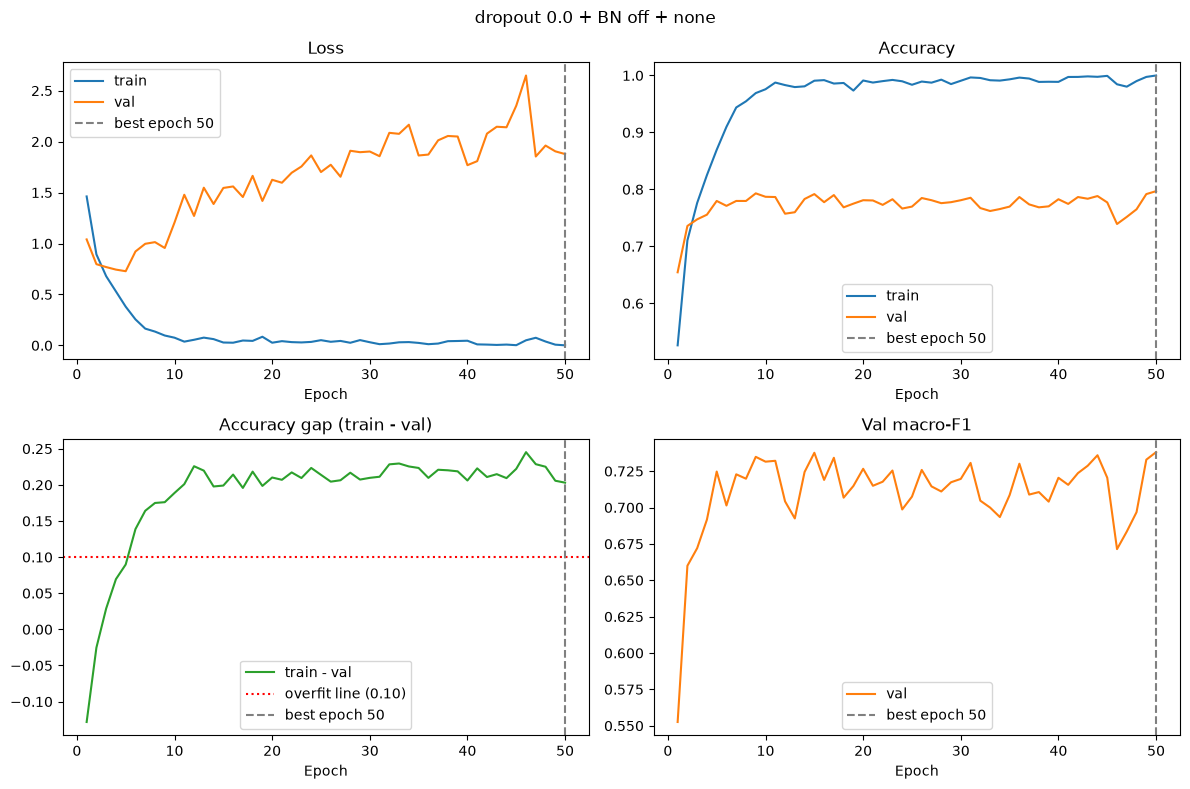

,best_epoch,val_f1,val_acc,train_acc,gap,overfit_start,val_loss_min_epoch,f1_last10
dropout 0.0 + BN off + none,50,0.738,0.797,1.0,0.203,6,5,0.715


In [ ]:
# E0 결과를 곡선과 결과표로 정리하는 코드임
#  - 이름은 그래프 제목에도 쓰여서 영어로 적음 (Colab에 한글 폰트가 없음)
report(hist_e0, E0_NAME)

# 하이퍼 파라미터 튜닝

### Optuna 하이퍼파라미터 탐색
- 그리드 서치는 조합을 전부 끝까지 학습함 → 하이퍼파라미터가 늘면 시간이 곱으로 늘어남
- Optuna는 두 가지로 시간을 줄임
  1. **다음 조합을 골라서 시도함**(TPE, 베이지안 최적화의 한 종류): 앞의 결과를 보고 좋은 영역을 더 자주 시도함
  2. **가망 없는 시도를 중간에 멈춤**(pruning): epoch마다 val macro-F1을 보고, 같은 epoch의 다른 시도들의 중앙값보다 낮으면 중단함
- 탐색 범위

| 하이퍼파라미터 | 값 | 비고 |
|---|---|---|
| Dropout | 0 ~ 0.5 (0.05 간격) | 분류부 (파라미터의 91.5%) |
| BatchNorm | off / on | 특징 추출부 (Conv 4개) |
| 증강 | none / weak / strong / trivial | trivial = 자동 증강, 색 변환 제외 (2-4) |
| 지우기 (RandomErasing) | 안 함 / 함 | 배경·워터마크 지름길 대응 (2-4) |
| 불균형 처리 | 없음 / 클래스 가중치 / 오버샘플링 | 1-2: 최대/최소 8.8배 |
| 학습률 | 1e-4 ~ 3e-3 (로그 간격) | Adam |

- 고정 조건: 128px, batch 64, Adam, **최대 100 epoch**, SEED 12345
- 중단 규칙: 처음 5번은 중단 없이 끝까지 학습함(비교 기준을 쌓기 위함), **30 epoch 전에는 중단하지 않음**
  - 규제가 강한 조합일수록 늦게 좋아짐 → 일찍 끊으면 좋은 조합이 잘림
- 첫 시도: 이전에 Colab에서 한 그리드 탐색(Dropout 6 × BN 2 × 증강 3 = 36개, 50 epoch)의 1위 조합
  (Dropout 0.5 + BN off + weak, val macro-F1 0.820, 최적 epoch 49)을 100 epoch으로 학습함
  → 이 PC 분할에서의 기준점이 되고, 탐색의 좋은 출발점이 됨
- 시도 횟수: 끝난 시도 25번 (한 번 실행에 최대 4시간 → 넘으면 멈추고, 다시 실행하면 이어서 함)
- 최종 모델 선택 규칙 (지금까지와 같음): 끝까지 학습한 시도 중 val macro-F1 1위, 1위와 0.02 안이면 동점 → 마지막 10 epoch 평균 F1이 높은 쪽

In [ ]:
import optuna

# 3-7. Optuna로 하이퍼파라미터를 탐색하는 코드임
#  - 시도(trial) 하나 = 하이퍼파라미터 조합 하나를 run()으로 학습하고 val macro-F1(최적 epoch)을 점수로 돌려줌
#  - 저장
#    - 탐색 기록(어떤 조합을 시도했고 점수가 얼마였는지, epoch별 점수)은 CACHE_DIR/optuna.db 파일에 저장됨
#      → 중간에 끊겨도 다시 실행하면 이어서 함 / 다 끝난 뒤에는 학습 없이 기록만 불러옴
#    - 끝까지 학습한 시도는 run()이 학습 결과(.pt)를 저장함 → 3-8에서 학습 없이 불러옴
#    - 실험 이름은 하이퍼파라미터로 만듦 → 같은 설정이면 같은 이름이라 저장 파일을 그대로 불러옴
#  - RUN_OPTUNA: 남은 시도를 실행할지 정하는 스위치임
#    - False(기본): 저장된 탐색 기록만 불러옴 → Run All을 해도 몇 시간짜리 탐색이 시작되지 않음
#    - True: 끝난 시도가 N_TRIALS보다 적으면 남은 시도를 실행함
#  - 중간에 중단된 시도는 학습 결과(.pt)를 저장하지 않음 (epoch별 점수는 optuna.db에 남음)

RUN_OPTUNA = False
N_TRIALS = 25            # 목표: 끝난 시도(끝까지 학습 + 중간에 중단) 수
TIMEOUT = 4 * 3600       # 한 번 실행할 때 최대 시간(초)
EPOCHS = 100             # 시도마다 최대 epoch

# 이전 그리드 탐색(Colab, 36개 조합)의 1위 조합 → 첫 시도로 넣음
GRID_BEST = {'dropout': 0.5, 'BN': 'off', 'aug': 'weak', 'erase': False, 'imbalance': 'none', 'lr': 1e-3}

def trial_name(p) :
    # 하이퍼파라미터로 실험 이름(= 저장 파일 이름)을 만듦
    #  - 기본값(지우기 안 함, 불균형 처리 없음, lr 1e-3)은 이름에서 뺌 → 기준 모델과 같은 이름 규칙
    #  - 예: GRID_BEST → 'dropout 0.5 + BN off + weak (100 epochs)'
    name = f"dropout {p['dropout']:g} + BN {p['BN']} + {p['aug']}"
    if p['erase'] :
        name += ' + erase'
    if p['imbalance'] != 'none' :
        name += f" + {p['imbalance']}"
    if p['lr'] != 1e-3 :
        name += f" + lr {p['lr']:.1e}"
    return name + f' ({EPOCHS} epochs)'

def objective(trial) :
    # (1) Optuna가 이번에 시도할 하이퍼파라미터를 고름 (탐색 범위 = 위 표)
    p = {'dropout': trial.suggest_float('dropout', 0.0, 0.5, step = 0.05),
         'BN': trial.suggest_categorical('BN', ['off', 'on']),
         'aug': trial.suggest_categorical('aug', ['none', 'weak', 'strong', 'trivial']),
         'erase': trial.suggest_categorical('erase', [False, True]),
         'imbalance': trial.suggest_categorical('imbalance', ['none', 'weight', 'oversample']),
         'lr': trial.suggest_float('lr', 1e-4, 3e-3, log = True)}
    name = trial_name(p)
    trial.set_user_attr('name', name)                  # 3-8에서 저장 파일을 찾을 때 씀

    # (2) epoch마다 점수를 Optuna에 알리고, 중앙값보다 낮으면(30 epoch 이후) 학습을 멈춤
    reported = []
    def on_epoch(epoch, f1) :
        reported.append(epoch)
        trial.report(f1, epoch)
        if trial.should_prune() :
            raise optuna.TrialPruned()

    # (3) 학습 (저장 파일이 있으면 불러옴)
    _, h = run(name, dropout = p['dropout'], use_bn = p['BN'] == 'on', aug = p['aug'], epochs = EPOCHS,
               lr = p['lr'], erase = p['erase'], imbalance = p['imbalance'], on_epoch = on_epoch, verbose = False)

    # 저장 파일을 불러온 경우에는 epoch별 점수를 한꺼번에 알려 줌 (다른 시도의 중단 기준 계산에 쓰임)
    if not reported :
        for e, f in zip(h['epoch'], h['val_f1']) :
            trial.report(f, int(e))
    return h['val_f1'].max()

def show(study, t) :
    # 시도가 끝날 때마다 한 줄씩 출력함 (val F1 = 그 시도가 도달한 최고 점수)
    v = f'{max(t.intermediate_values.values()):.3f}' if t.intermediate_values else '-'
    print(f"trial {t.number:2d} | {t.state.name:8s} | val F1 {v} | epochs {len(t.intermediate_values):3d} | {t.user_attrs.get('name')}")

# 탐색 기록 파일(optuna.db)을 만들거나 불러옴
storage = 'sqlite:///' + os.path.join(CACHE_DIR, 'optuna.db').replace('\\', '/')
study = optuna.create_study(study_name = 'garbage_cnn', storage = storage, direction = 'maximize', load_if_exists = True,
                            sampler = optuna.samplers.TPESampler(seed = SEED),
                            pruner = optuna.pruners.MedianPruner(n_startup_trials = 5, n_warmup_steps = 30))

done = [t for t in study.trials if t.state.name in ('COMPLETE', 'PRUNED')]
waiting = [t for t in study.trials if t.state.name == 'WAITING']
if trial_name(GRID_BEST) not in [t.user_attrs.get('name') for t in done] and not waiting :
    study.enqueue_trial(GRID_BEST)                     # 첫 시도로 이전 그리드 1위 조합을 넣음

if RUN_OPTUNA and len(done) < N_TRIALS :
    optuna.logging.set_verbosity(optuna.logging.WARNING)   # Optuna 자체 로그는 줄이고 show()로 한 줄씩 출력함
    study.optimize(objective, n_trials = N_TRIALS - len(done), timeout = TIMEOUT, callbacks = [show])

done = [t for t in study.trials if t.state.name in ('COMPLETE', 'PRUNED')]
print(f"끝난 시도: {len(done)} / {N_TRIALS} (끝까지 학습 {sum(t.state.name == 'COMPLETE' for t in done)}, 중간에 중단 {sum(t.state.name == 'PRUNED' for t in done)})")

[I 2026-11-19 06:33:17,977] Using an existing study with `study_name='garbage_cnn'` instead of creating a new one.


끝난 시도: 6 / 25 (끝까지 학습 6, 중간에 중단 0)


### 탐색 결과와 최종 모델 선택

In [ ]:
# Optuna 탐색 결과를 표로 정리하고 최종 모델을 고르는 코드임
#  - 끝까지 학습한 시도(COMPLETE)는 저장 파일에서 학습 기록을 불러와 f1_last10(마지막 10 epoch 평균 F1)을 계산함
#  - val_f1 = 그 시도가 도달한 최고 val macro-F1 (중단된 시도는 멈추기 전까지의 최고)
#  - 최종 모델 선택 규칙 (3-7 설명과 같음)
#    1. 끝까지 학습한 시도 중 val macro-F1 1위를 찾음
#    2. 1위와 0.02 안의 시도는 동점으로 봄 → 그중 f1_last10이 가장 높은 시도를 최종 모델로 고름
#  - 중간에 중단된 시도(PRUNED)는 끝까지 학습하지 않아서 후보에서 뺌 (표에는 참고로 같이 보여 줌)
#  - best_run(최종 모델 이름)과 best_model(최적 가중치가 들어간 모델)은 3-9, 최종 평가에서 씀

rows = []
for t in study.trials :
    if t.state.name not in ('COMPLETE', 'PRUNED') :
        continue
    row = {'trial': t.number, 'state': t.state.name,
           'val_f1': max(t.intermediate_values.values()),
           'epochs': len(t.intermediate_values), **t.params, 'name': t.user_attrs['name']}
    if t.state.name == 'COMPLETE' :                    # 저장 파일에서 학습 기록을 불러옴 (학습하지 않음)
        p = t.params
        _, h = run(row['name'], dropout = p['dropout'], use_bn = p['BN'] == 'on', aug = p['aug'], epochs = EPOCHS,
                   lr = p['lr'], erase = p['erase'], imbalance = p['imbalance'], train = False, verbose = False)
        row['best_epoch'] = int(h.loc[h['val_f1'].idxmax(), 'epoch'])
        row['f1_last10'] = h['val_f1'].tail(10).mean()
    rows.append(row)

trials_df = pd.DataFrame(rows).sort_values('val_f1', ascending = False).reset_index(drop = True)
trials_df.index = trials_df.index + 1                  # 순위를 1부터 매김
show_cols = ['trial', 'state', 'val_f1', 'f1_last10', 'best_epoch', 'epochs', 'dropout', 'BN', 'aug', 'erase', 'imbalance', 'lr']
display(trials_df[show_cols].round({'val_f1': 3, 'f1_last10': 3, 'dropout': 2, 'lr': 5}))

# 최종 모델 선택: 1위 − 0.02 안에서 f1_last10이 가장 높은 시도
complete = trials_df[trials_df['state'] == 'COMPLETE']
tie = complete[complete['val_f1'] >= complete['val_f1'].max() - 0.02]
final = tie.loc[tie['f1_last10'].idxmax()]
print(f"동점 후보 {len(tie)}개 (val F1 {complete['val_f1'].max() - 0.02:.3f} 이상) → 최종: trial {final['trial']} | {final['name']}")

best_run = final['name']
best_model, _ = run(best_run, dropout = final['dropout'], use_bn = final['BN'] == 'on', aug = final['aug'], epochs = EPOCHS,
                    lr = final['lr'], erase = final['erase'], imbalance = final['imbalance'], train = False)
best_model.eval()                                       # 평가 모드 (Dropout 끔)

# 참고: 첫 시도(이전 그리드 1위 조합)를 50 epoch까지만 봤을 때와 100 epoch까지 봤을 때의 최고 val F1 (같은 학습 기록 안에서 비교)
gb = complete[(complete[list(GRID_BEST)] == pd.Series(GRID_BEST)).all(axis = 1)]   # 하이퍼파라미터 값이 GRID_BEST와 같은 시도
if len(gb) > 0 :
    h = hists[gb.iloc[0]['name']]
    for last in [50, 100] :
        part = h[h['epoch'] <= last]
        b = part.loc[part['val_f1'].idxmax()]
        print(f"그리드 1위 조합 | 1~{last} epoch 중 최고: val macro-F1 {b['val_f1']:.3f} (epoch {int(b['epoch'])})")

최적 epoch: 80 (val macro-F1 0.825) | 저장된 결과를 불러옴 ← C:\Users\user\bigdata_cache\split_f2cb2ddc\dropout 0.5 + BN off + weak (100 epochs).pt
최적 epoch: 100 (val macro-F1 0.812) | 저장된 결과를 불러옴 ← C:\Users\user\bigdata_cache\split_f2cb2ddc\dropout 0.5 + BN off + trivial + erase + oversample + lr 1.0e-04 (100 epochs).pt
최적 epoch: 92 (val macro-F1 0.831) | 저장된 결과를 불러옴 ← C:\Users\user\bigdata_cache\split_f2cb2ddc\dropout 0.05 + BN on + strong + erase + lr 1.2e-03 (100 epochs).pt
최적 epoch: 94 (val macro-F1 0.803) | 저장된 결과를 불러옴 ← C:\Users\user\bigdata_cache\split_f2cb2ddc\dropout 0.5 + BN on + trivial + erase + weight + lr 2.1e-03 (100 epochs).pt
최적 epoch: 96 (val macro-F1 0.775) | 저장된 결과를 불러옴 ← C:\Users\user\bigdata_cache\split_f2cb2ddc\dropout 0.4 + BN off + none + lr 1.8e-04 (100 epochs).pt
최적 epoch: 84 (val macro-F1 0.831) | 저장된 결과를 불러옴 ← C:\Users\user\bigdata_cache\split_f2cb2ddc\dropout 0.4 + BN off + trivial + weight + lr 1.5e-04 (100 epochs).pt


,trial,state,val_f1,f1_last10,best_epoch,epochs,dropout,BN,aug,erase,imbalance,lr
1,2,COMPLETE,0.831,0.811,92,100,0.05,on,strong,True,none,0.00120
2,5,COMPLETE,0.831,0.817,84,100,0.40,off,trivial,False,weight,0.00015
3,0,COMPLETE,0.825,0.811,80,100,0.50,off,weak,False,none,0.00100
4,1,COMPLETE,0.812,0.805,100,100,0.50,off,trivial,True,oversample,0.00010
5,3,COMPLETE,0.803,0.788,94,100,0.50,on,trivial,True,weight,0.00210
6,4,COMPLETE,0.775,0.766,96,100,0.40,off,none,False,none,0.00018


동점 후보 4개 (val F1 0.811 이상) → 최종: trial 5 | dropout 0.4 + BN off + trivial + weight + lr 1.5e-04 (100 epochs)
 epoch  train_loss  val_loss  train_acc  val_acc  val_f1
     1       2.089     1.627      0.294    0.455   0.387
     2       1.695     1.388      0.435    0.552   0.506
     3       1.544     1.220      0.490    0.590   0.526
     4       1.471     1.149      0.522    0.651   0.600
     5       1.389     1.113      0.541    0.642   0.594
     6       1.319     1.054      0.568    0.663   0.607
     7       1.291     1.033      0.580    0.673   0.634
     8       1.270     0.970      0.593    0.693   0.653
     9       1.233     0.942      0.599    0.714   0.667
    10       1.186     0.920      0.618    0.707   0.672
    11       1.156     0.875      0.619    0.722   0.679
    12       1.157     0.871      0.622    0.728   0.690
    13       1.110     0.876      0.634    0.719   0.682
    14       1.079     0.830      0.642    0.727   0.688
    15       1.074     0.794      0.

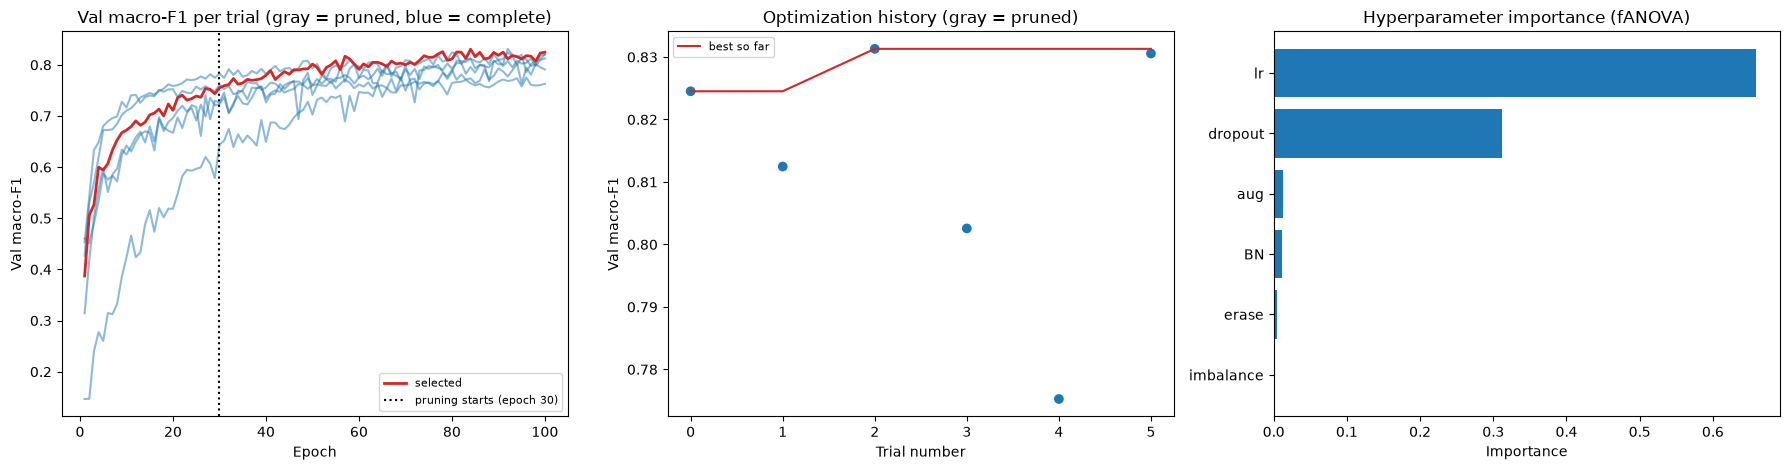

aug,none,strong,trivial,weak
mean,0.775,0.831,0.815,0.825
max,0.775,0.831,0.831,0.825
count,1.000,1.000,3.000,1.000


erase,False,True
mean,0.810,0.815
max,0.831,0.831
count,3.000,3.000


imbalance,none,oversample,weight
mean,0.810,0.812,0.817
max,0.831,0.812,0.831
count,3.000,1.000,2.000


BN,off,on
mean,0.811,0.817
max,0.831,0.831
count,4.000,2.000


In [ ]:
# Optuna 탐색 과정을 그래프로 보는 코드임
#  - (1) 시도별 val macro-F1 곡선: 회색 = 중간에 중단된 시도, 파랑 = 끝까지 학습한 시도, 빨강 = 최종 모델
#        → 점선(30 epoch) 이후 중앙값보다 낮은 시도가 일찍 멈추는 것을 볼 수 있음 = 시간을 아낀 부분
#  - (2) 시도 순서별 점수: 점 = 각 시도가 도달한 최고 val macro-F1, 선 = 그때까지의 최고값
#        → 뒤로 갈수록 좋은 점수가 자주 나오면 Optuna가 좋은 영역을 찾아간 것임
#  - (3) 하이퍼파라미터 중요도: 점수 차이를 어떤 하이퍼파라미터가 얼마나 설명하는지 (Optuna의 fANOVA, 끝까지 학습한 시도 기준)
#        → 시도 수가 적어서(25번) 대략적인 경향으로만 봄

trials = [t for t in study.trials if t.state.name in ('COMPLETE', 'PRUNED')]
fig, axes = plt.subplots(1, 3, figsize = (18, 4.8))

for t in trials :                                                     # (1)
    steps = sorted(t.intermediate_values)
    vals = [t.intermediate_values[s] for s in steps]
    if t.user_attrs.get('name') == best_run :
        axes[0].plot(steps, vals, color = 'tab:red', linewidth = 2, label = 'selected', zorder = 3)
    elif t.state.name == 'COMPLETE' :
        axes[0].plot(steps, vals, color = 'tab:blue', alpha = 0.5)
    else :
        axes[0].plot(steps, vals, color = 'gray', alpha = 0.4)
axes[0].axvline(30, color = 'black', linestyle = ':', label = 'pruning starts (epoch 30)')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Val macro-F1')
axes[0].set_title('Val macro-F1 per trial (gray = pruned, blue = complete)')
axes[0].legend(fontsize = 8)

nums = [t.number for t in trials]                                     # (2)
vals = [max(t.intermediate_values.values()) for t in trials]          # 시도마다 도달한 최고 val F1
axes[1].scatter(nums, vals, c = ['tab:blue' if t.state.name == 'COMPLETE' else 'gray' for t in trials])
axes[1].plot(nums, pd.Series(vals).cummax(), color = 'tab:red', label = 'best so far')
axes[1].set_xlabel('Trial number')
axes[1].set_ylabel('Val macro-F1')
axes[1].set_title('Optimization history (gray = pruned)')
axes[1].legend(fontsize = 8)

imp = optuna.importance.get_param_importances(study)                  # (3)
axes[2].barh(list(imp.keys())[::-1], list(imp.values())[::-1])
axes[2].set_xlabel('Importance')
axes[2].set_title('Hyperparameter importance (fANOVA)')

plt.tight_layout()
plt.show()

# 범주형 하이퍼파라미터의 값별 점수 (끝까지 학습한 시도만 / 시도 수가 적은 값은 흔들림이 큼)
for col in ['aug', 'erase', 'imbalance', 'BN'] :
    display(complete.groupby(col)['val_f1'].agg(['mean', 'max', 'count']).round(3).T)

### 최종 모델 학습 곡선

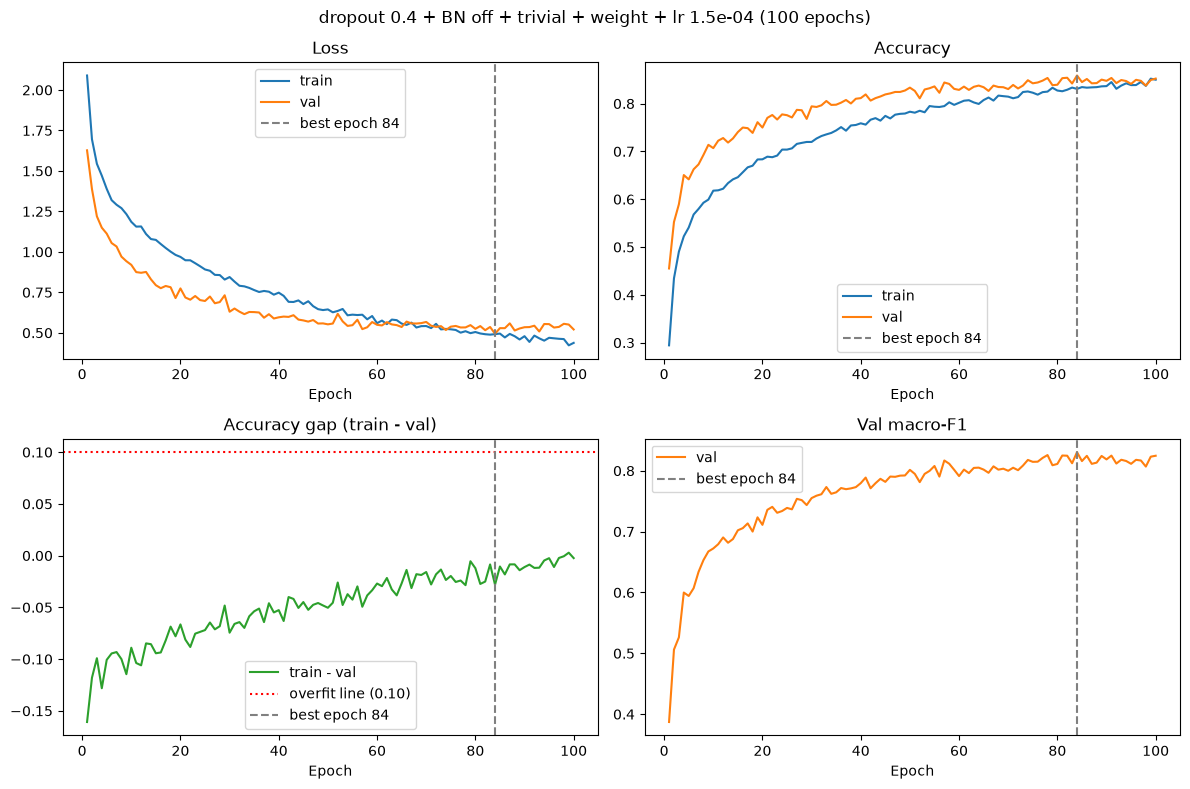

,best_epoch,val_f1,val_acc,train_acc,gap,overfit_start,val_loss_min_epoch,f1_last10
dropout 0.4 + BN off + trivial + weight + lr 1.5e-04 (100 epochs),84,0.831,0.859,0.831,-0.028,<NA>,84,0.817


In [ ]:
# 최종 모델의 학습 곡선 4개와 결과 한 줄을 보여 주는 코드임 (3-6의 report)
#  - 저장된 학습 기록(hists)을 쓰므로 다시 학습하지 않음
#  - 최적 epoch(회색 점선)이 100에 가까우면 아직 덜 배운 상태임 → epoch을 더 늘려 볼 여지가 있음
report(hists[best_run], best_run)

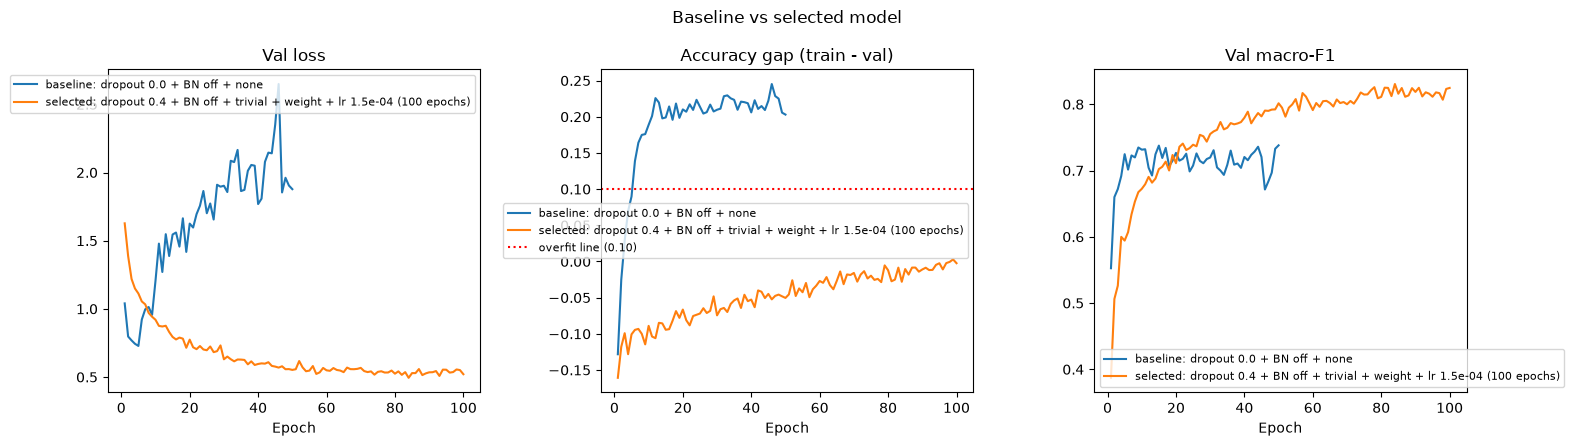

In [ ]:
# 기준 모델(E0)과 최종 모델의 학습 곡선을 겹쳐 그려서 규제·증강의 효과를 보여 주는 코드임
#  - (1) Val loss: 기준 모델은 일찍 최저점을 찍고 계속 올라감(과적합) → 최종 모델이 얼마나 덜 올라가는지 봄
#  - (2) 정확도 차이: 빨간 점선(0.10) 위면 과적합 기준을 넘은 것임
#        최종 모델은 Dropout·증강이 있어서 train 정확도가 낮게 재지므로 차이가 작게 나옴 → val loss와 함께 판단함
#  - (3) Val macro-F1: 최종 모델이 기준 모델보다 얼마나 높고, 덜 흔들리는지 봄

fig, axes = plt.subplots(1, 3, figsize = (16, 4.5))
for name, label in [(E0_NAME, 'baseline'), (best_run, 'selected')] :
    h = hists[name]
    axes[0].plot(h['epoch'], h['val_loss'], label = f'{label}: {name}')
    axes[1].plot(h['epoch'], h['train_acc'] - h['val_acc'], label = f'{label}: {name}')
    axes[2].plot(h['epoch'], h['val_f1'], label = f'{label}: {name}')
axes[1].axhline(0.10, color = 'red', linestyle = ':', label = 'overfit line (0.10)')
axes[0].set_title('Val loss')
axes[1].set_title('Accuracy gap (train - val)')
axes[2].set_title('Val macro-F1')
for ax in axes :
    ax.set_xlabel('Epoch')
    ax.legend(fontsize = 8)
fig.suptitle('Baseline vs selected model')
plt.tight_layout()
plt.show()

# 최종 평가 (test, 한 번만)

In [ ]:
# 최종 모델로 test 데이터를 한 번만 예측하는 코드임
#  - test는 최종 모델을 고른 뒤 여기서 처음이자 마지막으로 씀 (그 전에는 모델을 고르는 데 전혀 쓰지 않았음)
#    → 이 결과를 보고 모델을 다시 고치면 test가 val처럼 되어버리므로, 여기 결과는 그대로 보고함
#  - 정답(y_true), 예측(y_pred), 클래스별 확률(probs), 확신도(conf)를 저장해 두고 아래 셀들이 모두 같이 씀
#    → 같은 예측을 셀마다 다시 하지 않음
#  - softmax: 모델이 낸 클래스별 점수를 0~1 확률로 바꿈 (12개 합 = 1) → 가장 큰 확률 = 확신도

best_model.eval()                                   # 평가 모드 (Dropout 끔)
probs, y_true = [], []
with torch.no_grad() :                              # 기울기 계산 없이 예측만 함
    for xb, yb in test_loader :
        out = best_model(xb.to(device))
        probs.append(torch.softmax(out, dim = 1).cpu())
        y_true.append(yb)

probs = torch.cat(probs).numpy()                    # (2324, 12): 사진마다 12개 클래스의 확률
y_true = torch.cat(y_true).numpy()                  # (2324,): 정답 번호
y_pred = probs.argmax(axis = 1)                     # 확률이 가장 큰 클래스 = 예측
conf = probs.max(axis = 1)                          # 예측한 클래스의 확률 = 확신도
print('test 장수:', len(y_true))

test 장수: 2324


In [ ]:
# test 전체 성능을 val과 비교하는 코드임
#  - accuracy: 전체 중 맞힌 비율 / macro-F1: 12개 클래스 F1의 단순 평균 (주지표)
#  - val 값 = 최종 모델의 최적 epoch 값 (3-8에서 고른 시도의 학습 기록)
#  - test가 val과 비슷하면: 여러 시도 중에서 val로 고르는 과정이 val에만 맞춰지지(과적합) 않았다는 근거임
#    (여러 시도 중 val이 가장 높은 것을 골랐으므로 test가 val보다 조금 낮게 나오는 것은 자연스러움)
#  - 비교용 기준선: 모든 사진을 가장 많은 클래스(clothes)로 찍기만 해도 정확도가 약 0.34가 나옴
#    → 불균형 데이터에서 정확도만 보면 성능이 부풀려 보이는 이유임 (이때 macro-F1은 약 0.04)

val_best = hists[best_run].loc[hists[best_run]['val_f1'].idxmax()]     # val 최적 epoch의 행
overall = pd.DataFrame({
    'accuracy': [val_best['val_acc'], (y_pred == y_true).mean()],
    'macro-F1': [val_best['val_f1'], f1_score(y_true, y_pred, average = 'macro')],
}, index = ['val (best epoch)', 'test'])
display(overall.round(3))

majority = np.full_like(y_true, class_to_idx['clothes'])              # 전부 clothes로 예측한 경우
print('기준선(전부 clothes) → accuracy', round((majority == y_true).mean(), 3),
      '| macro-F1', round(f1_score(y_true, majority, average = 'macro', zero_division = 0), 3))

,accuracy,macro-F1
val (best epoch),0.859,0.831
test,0.849,0.812


기준선(전부 clothes) → accuracy 0.344 | macro-F1 0.043


,precision,recall,f1,test_n,train_n
plastic,0.709,0.698,0.703,129,605
metal,0.704,0.704,0.704,115,538
white-glass,0.774,0.767,0.771,116,540
shoes,0.801,0.758,0.779,297,1384
biological,0.758,0.824,0.790,148,689
battery,0.831,0.761,0.794,142,661
trash,0.835,0.779,0.806,104,488
paper,0.794,0.860,0.826,157,735
brown-glass,0.810,0.890,0.848,91,425
cardboard,0.904,0.843,0.873,134,623


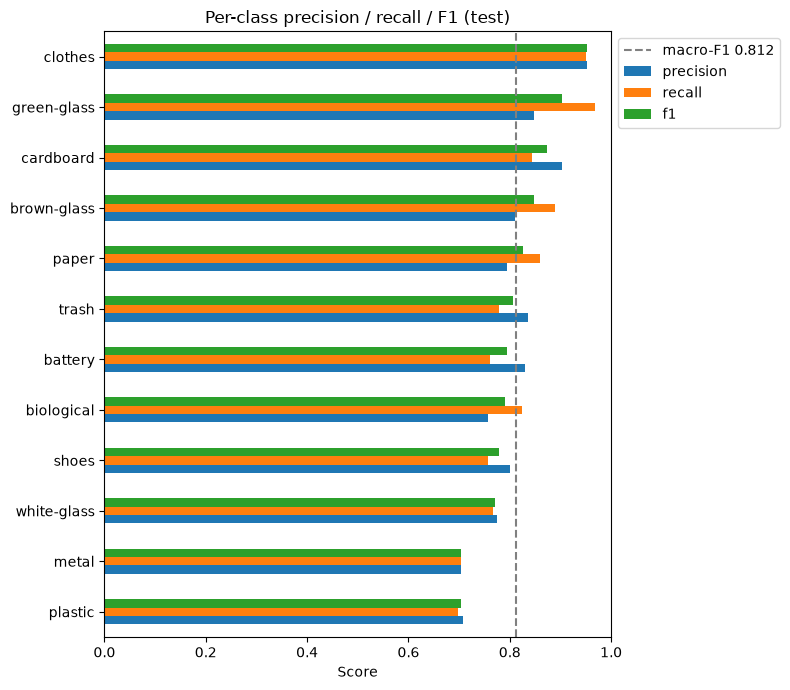

In [ ]:
from sklearn.metrics import precision_recall_fscore_support

# 클래스별 정밀도·재현율·F1을 표와 막대그래프로 보는 코드임
#  - recall(재현율)   : 실제 그 클래스인 사진 중 맞힌 비율 = '클래스별 정답률'
#  - precision(정밀도): 그 클래스라고 예측한 사진 중 실제로 맞은 비율 → 낮으면 다른 클래스를 그 클래스로 많이 착각한 것임
#  - f1               : 두 값의 조화평균 → 12개 클래스 f1의 단순 평균이 macro-F1임
#  - test_n / train_n : 클래스별 test·train 장수 (4-5에서 불균형의 영향을 볼 때 씀)
#  - 특히 볼 클래스: battery(위험물이라 놓치면 안 됨), 유리 3종·plastic·paper·cardboard(EDA에서 헷갈릴 것으로 예상함)

prec, rec, f1, test_n = precision_recall_fscore_support(y_true, y_pred, labels = range(len(CLASSES)), zero_division = 0)   # 클래스 번호(0~11) 순서
per_class = pd.DataFrame({'precision': prec, 'recall': rec, 'f1': f1, 'test_n': test_n,
                          'train_n': np.bincount(labels['train'].numpy(), minlength = len(CLASSES))},
                         index = CLASSES).sort_values('f1')          # f1이 낮은 클래스부터
display(per_class.round(3))

ax = per_class[['precision', 'recall', 'f1']].plot.barh(figsize = (8, 7))
ax.axvline(per_class['f1'].mean(), color = 'gray', linestyle = '--', label = f"macro-F1 {per_class['f1'].mean():.3f}")
ax.set_xlim(0, 1)
ax.set_xlabel('Score')
ax.set_title('Per-class precision / recall / F1 (test)')
ax.legend(loc = 'upper left', bbox_to_anchor = (1, 1))          # 범례를 그래프 오른쪽 바깥에 둠 (막대를 가리지 않게)
plt.tight_layout()
plt.show()

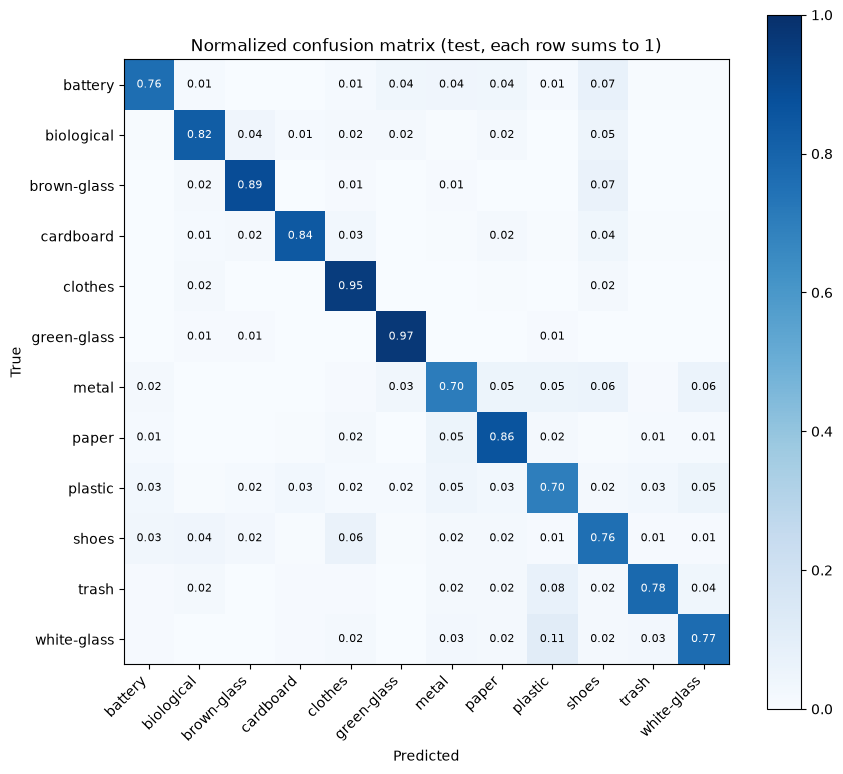

,true,pred,count,ratio
112,shoes,clothes,19,0.064
49,clothes,biological,17,0.021
57,clothes,shoes,13,0.016
140,white-glass,plastic,13,0.112
109,shoes,biological,12,0.040
108,shoes,battery,10,0.034
9,battery,shoes,10,0.070
128,trash,plastic,8,0.077
90,paper,metal,8,0.051
83,metal,white-glass,7,0.061


In [ ]:
from sklearn.metrics import confusion_matrix

# 혼동행렬로 어떤 클래스를 어떤 클래스로 착각하는지 보는 코드임
#  - 행 = 실제 클래스, 열 = 예측 클래스 / 각 행을 그 클래스의 장수로 나눈 비율로 그림
#    → 클래스마다 장수가 달라도(clothes 약 800장, brown-glass 약 90장) 같은 기준으로 비교할 수 있음
#  - 대각선 = 클래스별 재현율(4-3의 recall), 대각선 밖 = 다른 클래스로 착각한 비율
#  - 아래 표: 가장 많이 틀린 (실제 → 예측) 쌍 10개
#    → EDA에서 예상한 쌍(white-glass↔plastic, paper↔cardboard, 유리 3종끼리)이 실제로 많이 틀렸는지 확인함

cm = pd.DataFrame(confusion_matrix(y_true, y_pred, labels = range(len(CLASSES))), index = CLASSES, columns = CLASSES)   # 장수
cm_rate = cm.div(cm.sum(axis = 1), axis = 0)                                   # 행마다 비율로 바꿈

fig, ax = plt.subplots(figsize = (9, 8))
im = ax.imshow(cm_rate.values, cmap = 'Blues', vmin = 0, vmax = 1)
for i in range(len(CLASSES)) :
    for j in range(len(CLASSES)) :
        v = cm_rate.values[i, j]
        if v >= 0.01 :                                                         # 1% 미만은 생략해서 보기 쉽게 함
            ax.text(j, i, f'{v:.2f}', ha = 'center', va = 'center', fontsize = 8, color = 'white' if v > 0.5 else 'black')
ax.set_xticks(range(len(CLASSES)), CLASSES, rotation = 45, ha = 'right')
ax.set_yticks(range(len(CLASSES)), CLASSES)
ax.set_xlabel('Predicted')
ax.set_ylabel('True')
ax.set_title('Normalized confusion matrix (test, each row sums to 1)')
fig.colorbar(im, ax = ax)
plt.tight_layout()
plt.show()

# 대각선 밖(틀린 것)만 모아서 장수가 많은 순서로 10개
pairs = cm.rename_axis(index = 'true', columns = 'pred').stack().reset_index(name = 'count')
pairs = pairs[pairs['true'] != pairs['pred']].sort_values('count', ascending = False).head(10)
pairs['ratio'] = pairs['count'] / cm.sum(axis = 1)[pairs['true']].values       # 실제 클래스 장수 대비 비율
display(pairs.round(3))

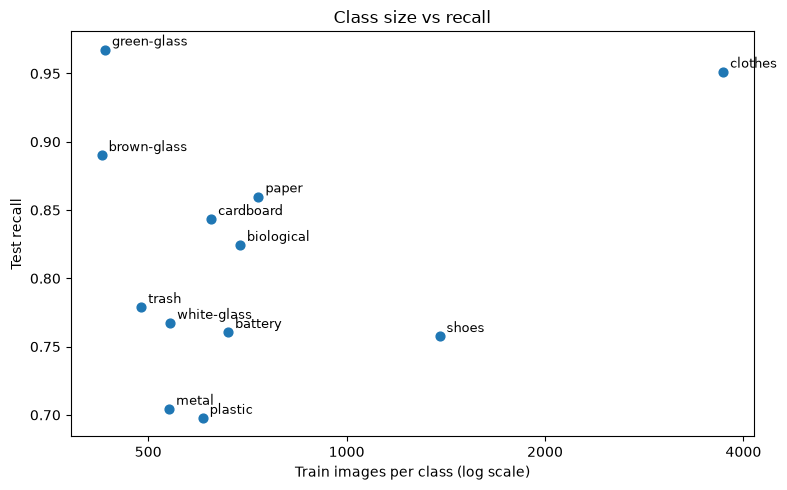

스피어만 상관계수: -0.07


In [ ]:
# 클래스 크기(train 장수)와 재현율의 관계를 보는 코드임 (4-3의 per_class 사용)
#  - 점 하나 = 클래스 하나 / 가로 = train 장수(로그 눈금), 세로 = test 재현율
#  - 오른쪽 위로 올라가는 모양이면: 데이터가 적은 클래스일수록 덜 맞힘 → 불균형의 영향이 있다는 뜻임
#  - 스피어만 상관계수: 장수 순위와 재현율 순위가 같이 움직이는 정도 (-1~1, 1에 가까울수록 '많을수록 잘 맞힘')
#  - 장수가 적은데도 재현율이 높은 클래스는 다른 클래스와 생김새가 뚜렷이 다르다고 해석할 수 있음

fig, ax = plt.subplots(figsize = (8, 5))
ax.scatter(per_class['train_n'], per_class['recall'], s = 40)
for c in per_class.index :
    ax.annotate(c, (per_class.loc[c, 'train_n'], per_class.loc[c, 'recall']),
                xytext = (5, 3), textcoords = 'offset points', fontsize = 9)    # 점 옆에 클래스 이름
ax.set_xscale('log')                                                # 장수가 425~3,727장으로 차이가 커서 로그 눈금을 씀
ax.set_xticks([500, 1000, 2000, 4000], ['500', '1000', '2000', '4000'])
ax.minorticks_off()
ax.set_xlabel('Train images per class (log scale)')
ax.set_ylabel('Test recall')
ax.set_title('Class size vs recall')
plt.tight_layout()
plt.show()
print('스피어만 상관계수:', round(per_class['train_n'].corr(per_class['recall'], method = 'spearman'), 3))

In [ ]:
# 12개 클래스를 분리수거 단위(재질 그룹)로 묶어서 정확도를 보는 코드임
#  - 실제 목적은 분리수거임 → 같은 그룹 안에서 틀린 것(예: green-glass → brown-glass)은 같은 수거함으로 가서 피해가 작음
#  - 그룹: glass(유리 3종), paper(paper·cardboard), textile(clothes·shoes), 나머지는 클래스 하나가 그룹 하나
#  - 결과 1: 12클래스 정확도 vs 재질 그룹 정확도
#  - 결과 2: 틀린 것 중 같은 그룹 안에서 틀린 비율 → 높을수록 오류가 덜 심각함
#  - 결과 3: 그룹별 정확도 (battery는 그룹 = 클래스라 4-3의 재현율과 같음)

GROUP = {'brown-glass': 'glass', 'green-glass': 'glass', 'white-glass': 'glass',
         'paper': 'paper', 'cardboard': 'paper',
         'clothes': 'textile', 'shoes': 'textile',
         'plastic': 'plastic', 'metal': 'metal', 'battery': 'battery',
         'biological': 'biological', 'trash': 'trash'}

g_true = np.array([GROUP[CLASSES[i]] for i in y_true])     # 정답의 재질 그룹
g_pred = np.array([GROUP[CLASSES[i]] for i in y_pred])     # 예측의 재질 그룹
wrong = y_true != y_pred

print('12클래스 정확도 :', round((~wrong).mean(), 3))
print('재질 그룹 정확도:', round((g_true == g_pred).mean(), 3))
print('틀린 것 중 같은 그룹 안에서 틀린 비율:', round((g_true[wrong] == g_pred[wrong]).mean(), 3), f'(틀린 {wrong.sum()}장 중)')

group_acc = pd.DataFrame({'group': g_true, 'correct': g_true == g_pred}).groupby('group')['correct'].agg(['mean', 'size'])
group_acc.columns = ['group_accuracy', 'test_n']
display(group_acc.sort_values('group_accuracy').round(3))

12클래스 정확도 : 0.849
재질 그룹 정확도: 0.865
틀린 것 중 같은 그룹 안에서 틀린 비율: 0.106 (틀린 350장 중)


,group_accuracy,test_n
group,,
plastic,0.698,129
metal,0.704,115
battery,0.761,142
trash,0.779,104
biological,0.824,148
paper,0.866,291
glass,0.870,299
textile,0.928,1096


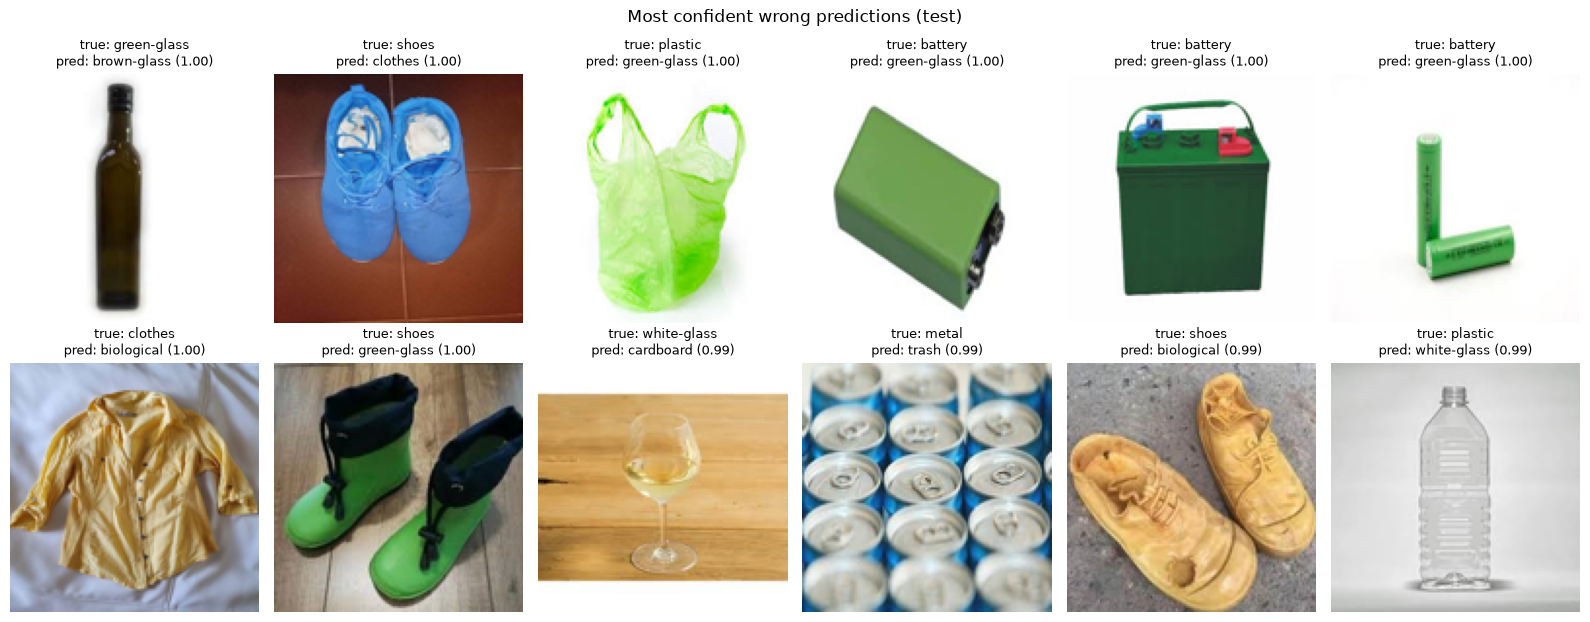

,file,true,pred,confidence
0,green-glass558.jpg,green-glass,brown-glass,1.000
1,shoes1844.jpg,shoes,clothes,1.000
2,plastic483.jpg,plastic,green-glass,1.000
3,battery13.jpg,battery,green-glass,0.999
4,battery4.jpg,battery,green-glass,0.998
5,battery12.jpg,battery,green-glass,0.998
6,clothes1281.jpg,clothes,biological,0.998
7,shoes541.jpg,shoes,green-glass,0.995
8,white-glass726.jpg,white-glass,cardboard,0.995
9,metal618.jpg,metal,trash,0.994


In [ ]:
# 모델이 높은 확신으로 틀린 test 사진을 보는 코드임
#  - 틀린 사진 중 확신도(예측 클래스의 확률)가 높은 순서로 12장을 보여 줌
#  - 확신하고 틀린 사진은 보통 다음 셋 중 하나임
#    (1) 라벨 오류: 예측은 맞는데 정답 라벨이 틀린 경우 (EDA 1-7에서 metal/white-glass 사례를 확인했음)
#    (2) 지름길 학습: 물체가 아니라 배경·워터마크·촬영 스타일을 보고 예측한 경우 (EDA 1-3)
#    (3) 진짜 어려운 사진: 사람이 봐도 헷갈리는 경우 (투명 플라스틱 vs 흰 유리 등)
#  - test_loader는 섞지 않았으므로(shuffle = False) 예측 순서 = images['test'] 순서 = test 표(2-2)의 행 순서임

wrong_idx = np.where(y_true != y_pred)[0]
top = wrong_idx[np.argsort(-conf[wrong_idx])][:12]          # 틀린 것 중 확신도가 높은 순서로 12장

fig, axes = plt.subplots(2, 6, figsize = (16, 6.5))
for ax, i in zip(axes.flat, top) :
    ax.imshow(images['test'][i].permute(1, 2, 0))             # (C, H, W) → (H, W, C)로 바꿔야 그림이 그려짐
    ax.set_title(f'true: {CLASSES[y_true[i]]}\npred: {CLASSES[y_pred[i]]} ({conf[i]:.2f})', fontsize = 9)
    ax.axis('off')
fig.suptitle('Most confident wrong predictions (test)')
plt.tight_layout()
plt.show()

# 파일 이름도 남겨 둠 → 원본 사진을 직접 열어 라벨 오류인지 확인할 때 씀
display(pd.DataFrame({'file': test['path'].iloc[top].apply(os.path.basename).values,
                      'true': [CLASSES[k] for k in y_true[top]],
                      'pred': [CLASSES[k] for k in y_pred[top]],
                      'confidence': conf[top].round(3)}))

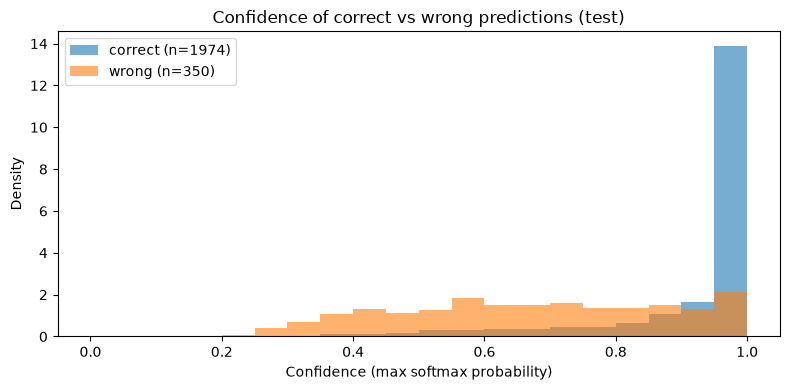

평균 확신도 → 맞힘 0.926 | 틀림 0.672
틀린 것 중 확신도 0.9 이상 비율: 0.171


In [ ]:
# 맞힌 사진과 틀린 사진의 확신도 분포를 비교하는 코드임
#  - 확신도 = 예측한 클래스의 확률 (0~1)
#  - 좋은 모델: 맞힐 때는 확신이 높고, 틀릴 때는 확신이 낮음 → 확신도가 낮은 사진만 사람이 다시 보게 할 수 있음
#  - 틀렸는데 확신도가 0.9 이상인 사진이 많으면 '확신하며 틀리는' 상태임
#    → 3-9 학습 곡선에서 val loss는 오르는데 F1은 오르는 구간이 있다면 그 이유와 연결됨
#      (loss는 확신하며 틀릴수록 크게 늘어남 → 맞히는 장수가 늘어도 loss는 오를 수 있음)
#  - 맞힌 사진이 훨씬 많아서 개수가 아니라 비율(density)로 그림 → 두 분포의 모양을 비교함

correct = y_true == y_pred
fig, ax = plt.subplots(figsize = (8, 4))
ax.hist(conf[correct], bins = 20, range = (0, 1), density = True, alpha = 0.6, label = f'correct (n={correct.sum()})')
ax.hist(conf[~correct], bins = 20, range = (0, 1), density = True, alpha = 0.6, label = f'wrong (n={(~correct).sum()})')
ax.set_xlabel('Confidence (max softmax probability)')
ax.set_ylabel('Density')
ax.set_title('Confidence of correct vs wrong predictions (test)')
ax.legend()
plt.tight_layout()
plt.show()

print('평균 확신도 → 맞힘', round(conf[correct].mean(), 3), '| 틀림', round(conf[~correct].mean(), 3))
print('틀린 것 중 확신도 0.9 이상 비율:', round((conf[~correct] >= 0.9).mean(), 3))

# CNN 개선

- 왜 구조를 바꾸는가
  - 기존 CNN은 하이퍼파라미터를 바꿔도 val macro-F1이 0.82~0.83 근처에서 멈춤 (Colab 그리드 top5가 0.809~0.820, Optuna도 비슷함)
    → 규제·증강보다 **모델 구조**가 한계라고 판단함
  - 기존 CNN은 파라미터 459만 개 중 91.5%가 Flatten 뒤 Linear(16,384 → 256) 한 층에 있음
    → 위치마다 다른 가중치를 배워서 '사진의 어느 위치에 무엇이 있었는지'까지 외우기 쉬움
    → 기준 모델(E0)은 train 정확도 1.000, val loss가 epoch 5 이후 계속 오름 = 과적합의 주원인
- 바꾼 점 (CNN2)
  1. 블록마다 Conv를 2번 쌓음: Conv → BN → ReLU → Conv → BN → ReLU → MaxPool (BatchNorm은 항상 켬)
  2. Flatten + 큰 Linear 대신 **Global Average Pooling(GAP)**: 채널마다 8×8 지도의 평균 하나만 남김 → 위치와 상관없이 '무엇이 있는지'로 분류함
  3. 분류부는 Dropout → Linear(256 → 12) 하나만 둠 → 파라미터가 약 1/4로 줄어듦
- 실험 (나머지 조건은 같음: 128px, batch 64, Adam, lr 1e-3, 100 epoch, SEED 12345, 내 PC 분할)

| 실험 | 증강 | 목적 |
|---|---|---|
| (A) CNN2 + weak | 반전만 | 기존 그리드 1위(기존 CNN + weak)와 데이터·학습 조건을 같게 함 → **구조만 바꾼 효과** |
| (B) CNN2 + strong + erase | strong + 사진 일부 지우기 | Optuna에서 가장 좋았던 증강 조합 → **과적합이 줄어든 구조에 강한 증강**을 더한 효과 |

- 고르는 규칙 (지금까지와 같음): val macro-F1 1위, 0.02 안이면 동점 → 마지막 10 epoch 평균 F1이 높은 쪽
- test는 고른 뒤 보고만 함 (어떤 모델을 쓸지는 val로만 정함)

In [ ]:
# 개선한 CNN 구조(CNN2)를 정의하는 코드임
#  - 블록 4개: 채널 32 → 64 → 128 → 256, 블록마다 크기가 절반이 됨 (128 → 64 → 32 → 16 → 8)
#    - 블록 = Conv 3x3 → BatchNorm → ReLU → Conv 3x3 → BatchNorm → ReLU → MaxPool
#    - 같은 크기에서 Conv를 한 번 더 거쳐 더 복잡한 모양(질감·투명도 등)을 잡게 함
#  - 분류부 = GAP → Flatten → Dropout → Linear(256 → 12)
#    - GAP(AdaptiveAvgPool2d(1)): 채널마다 8x8 지도의 평균 하나만 남김 → (batch, 256, 1, 1)
#    - 기존 CNN의 Linear(16,384 → 256)이 없어져서 '위치까지 외우는' 파라미터가 사라짐
#  - 마지막에 softmax를 넣지 않음 → CrossEntropyLoss가 내부에서 계산함 (기존 CNN과 같음)
#  - 아래에서 기존 CNN과 파라미터 수, 출력 모양을 비교함

class CNN2(nn.Module) :
    def __init__(self, dropout = 0.3, n_classes = 12) :
        super().__init__()
        layers = []
        for c_in, c_out in [(3, 32), (32, 64), (64, 128), (128, 256)] :     # 블록 4개
            layers += [nn.Conv2d(c_in, c_out, 3, padding = 1), nn.BatchNorm2d(c_out), nn.ReLU(),
                       nn.Conv2d(c_out, c_out, 3, padding = 1), nn.BatchNorm2d(c_out), nn.ReLU(),
                       nn.MaxPool2d(2)]
        self.features = nn.Sequential(*layers)
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),      # GAP: 채널마다 평균 하나 → (batch, 256, 1, 1)
            nn.Flatten(),                 # → (batch, 256)
            nn.Dropout(dropout),
            nn.Linear(256, n_classes),    # 출력 = 클래스 12개의 점수
        )

    def forward(self, x) :
        return self.classifier(self.features(x))

for label, m in [('CNN (old)', CNN(dropout = 0.5)), ('CNN2 (new)', CNN2())] :
    m.eval()
    n_feat = sum(prm.numel() for prm in m.features.parameters())
    n_cls = sum(prm.numel() for prm in m.classifier.parameters())
    out = m(torch.zeros(1, 3, IMG_SIZE, IMG_SIZE))                       # 가짜 이미지 1장으로 출력 모양 확인
    print(f'{label:10s} | 특징 추출부 {n_feat:>9,} | 분류부 {n_cls:>9,} | 전체 {n_feat + n_cls:>9,} | 출력 {tuple(out.shape)}')

CNN (old)  | 특징 추출부   388,416 | 분류부 4,197,644 | 전체 4,586,060 | 출력 (1, 12)
CNN2 (new) | 특징 추출부 1,174,176 | 분류부     3,084 | 전체 1,177,260 | 출력 (1, 12)


In [ ]:
# CNN2를 학습하는 코드임 (저장돼 있으면 불러옴)
#  - (A) CNN2 + weak, (B) CNN2 + strong + erase (위 표 참고)
#  - Dropout은 0.3 → 분류부가 Linear 1개로 작아져서 기존(0.5, 2곳)보다 약하게 둠
#  - run()은 기존 CNN만 만들기 때문에, 같은 순서(DataLoader → 시드 → 모델 → train_model)를 여기서 직접 씀
#    → train_model이 저장 파일(CACHE_DIR/이름.pt)이 있으면 불러오므로, 다시 실행해도 학습하지 않음
#  - 결과표(results)에 한 줄씩 기록함 (report, 그래프는 5-4에서 겹쳐 그림)
#  - 예상 시간: 처음 한 번만 (A) 약 30분, (B) 약 45분 (strong 증강을 CPU에서 계산해서 느림)

CNN2_EXPS = {'CNN2 + weak (100 epochs)': ('weak', False, 100),             # 이름: (증강, 지우기, epoch 수)
             'CNN2 + strong + erase (100 epochs)': ('strong', True, 100)}

cnn2_models = {}
for name, (aug, erase, epochs) in CNN2_EXPS.items() :
    print(f'========== {name} ==========')
    loader = make_train_loader(aug, erase = erase)                    # 증강·지우기에 맞는 train DataLoader (2-5)
    set_seed()                                                        # 지금까지와 같은 시드(12345)
    cnn2_models[name] = CNN2(dropout = 0.3)
    hists[name] = train_model(cnn2_models[name], loader, val_loader, name, epochs = epochs, verbose = False)
    report(hists[name], name, plot = False)

========== CNN2 + weak (100 epochs) ==========
최적 epoch: 94 (val macro-F1 0.877) | 저장된 결과를 불러옴 ← C:\Users\user\bigdata_cache\split_f2cb2ddc\CNN2 + weak (100 epochs).pt
========== CNN2 + strong + erase (100 epochs) ==========
최적 epoch: 95 (val macro-F1 0.864) | 저장된 결과를 불러옴 ← C:\Users\user\bigdata_cache\split_f2cb2ddc\CNN2 + strong + erase (100 epochs).pt


In [ ]:
# CNN2 실험 중 최종을 고르고, 기준 모델·기존 최종 모델과 val로 비교하는 코드임
#  - 고르는 규칙: val macro-F1 1위, 0.02 안이면 동점 → f1_last10(마지막 10 epoch 평균 F1)이 높은 쪽
#  - 비교 대상
#    - E0: 기준 모델 (규제·증강 없음, 50 epoch)
#    - 기존 최종: 3-8에서 Optuna로 고른 기존 CNN (best_run)
#    - CNN2 (A), (B)
#  - 모든 숫자는 val 기준임 → 어떤 모델을 쓸지는 val로만 정함
#  - params: 학습되는 파라미터 수

cand = pd.DataFrame.from_dict({n: results[n] for n in CNN2_EXPS}, orient = 'index')   # 행 = CNN2 실험, 열 = 지표
tie2 = cand[cand['val_f1'] >= cand['val_f1'].max() - 0.02]
cnn2_run = tie2['f1_last10'].idxmax()                                # CNN2 최종 실험 이름
cnn2_model = cnn2_models[cnn2_run]
cnn2_model.eval()
print(f'CNN2 동점 후보 {len(tie2)}개 → CNN2 최종: {cnn2_run}')

report(hists[E0_NAME], E0_NAME, plot = False)                        # 비교표에 들어갈 줄을 결과표에 확실히 넣어 둠
report(hists[best_run], best_run, plot = False)
names = [E0_NAME, best_run] + list(CNN2_EXPS)
cmp_val = pd.DataFrame.from_dict({n: results[n] for n in names}, orient = 'index')
cmp_val.insert(0, 'model', ['CNN (E0, baseline)', 'CNN (Optuna best)'] + ['CNN2'] * len(CNN2_EXPS))
cmp_val['params'] = [sum(prm.numel() for prm in m.parameters()) for m in [model_e0, best_model] + [cnn2_models[n] for n in CNN2_EXPS]]
cols = ['model', 'params', 'val_f1', 'f1_last10', 'best_epoch', 'val_acc', 'train_acc', 'gap', 'overfit_start', 'val_loss_min_epoch']
display(cmp_val[cols].round(3).astype({'overfit_start': 'Int64'}))

CNN2 동점 후보 2개 → CNN2 최종: CNN2 + weak (100 epochs)


,model,params,val_f1,f1_last10,best_epoch,val_acc,train_acc,gap,overfit_start,val_loss_min_epoch
dropout 0.0 + BN off + none,"CNN (E0, baseline)",4586060,0.738,0.715,50,0.797,1.000,0.203,6,5
dropout 0.4 + BN off + trivial + weight + lr 1.5e-04 (100 epochs),CNN (Optuna best),4586060,0.831,0.817,84,0.859,0.831,-0.028,<NA>,84
CNN2 + weak (100 epochs),CNN2,1177260,0.877,0.863,94,0.899,0.978,0.079,60,71
CNN2 + strong + erase (100 epochs),CNN2,1177260,0.864,0.845,95,0.888,0.915,0.028,<NA>,95


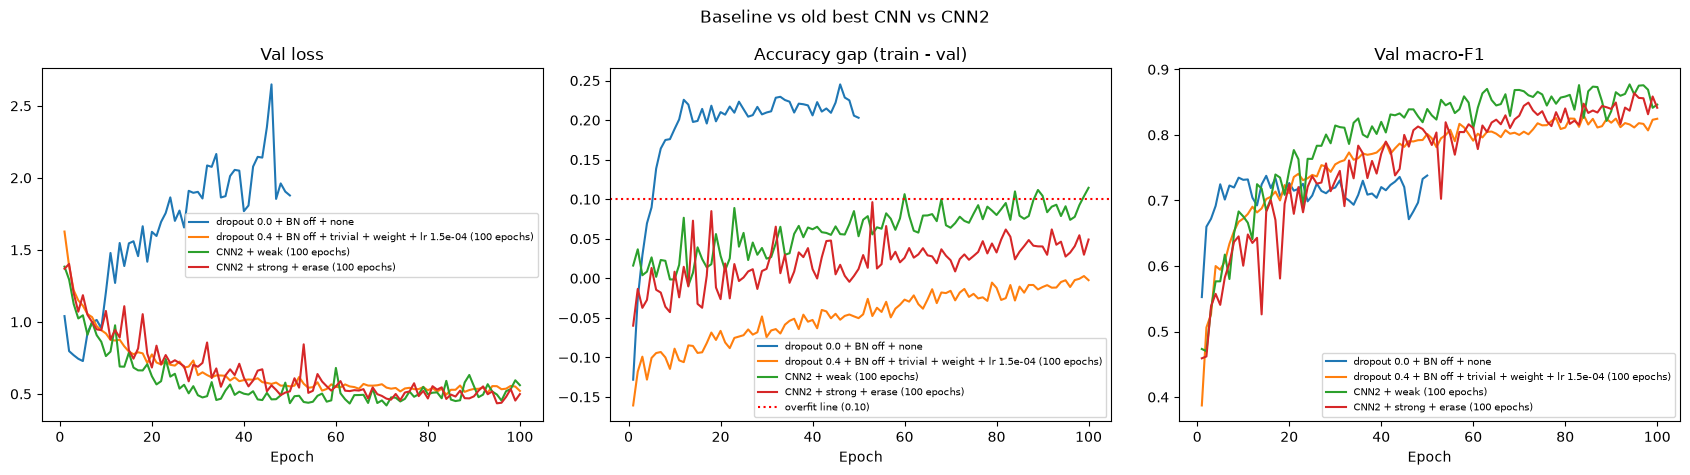

In [ ]:
# 기준 모델, 기존 최종 모델, CNN2 두 실험의 학습 곡선을 겹쳐 그리는 코드임
#  - (1) Val loss: 낮고, 늦게 올라갈수록 과적합이 덜한 것임
#  - (2) 정확도 차이(train − val): 빨간 점선(0.10) 위면 과적합 기준을 넘은 것임
#        (증강·Dropout이 있으면 train 정확도가 낮게 재지므로 val loss와 함께 판단함)
#  - (3) Val macro-F1: 높고 덜 흔들릴수록 좋음
#  - 학습 기록(hists)을 쓰므로 다시 학습하지 않음

fig, axes = plt.subplots(1, 3, figsize = (17, 4.8))
for name in names :
    h = hists[name]
    axes[0].plot(h['epoch'], h['val_loss'], label = name)
    axes[1].plot(h['epoch'], h['train_acc'] - h['val_acc'], label = name)
    axes[2].plot(h['epoch'], h['val_f1'], label = name)
axes[1].axhline(0.10, color = 'red', linestyle = ':', label = 'overfit line (0.10)')
axes[0].set_title('Val loss')
axes[1].set_title('Accuracy gap (train - val)')
axes[2].set_title('Val macro-F1')
for ax in axes :
    ax.set_xlabel('Epoch')
    ax.legend(fontsize = 7)
fig.suptitle('Baseline vs old best CNN vs CNN2')
plt.tight_layout()
plt.show()

#### test 평가: 기존 최종 모델 vs CNN2 최종 모델

In [ ]:
# 기존 최종 모델과 CNN2 최종 모델을 test로 평가하는 코드임
#  - 두 모델 모두 val로 고른 뒤 test를 처음 보는 것임 → test 점수로 다시 고르지 않고 보고만 함
#  - test_loader는 섞지 않았으므로(shuffle = False) 예측 순서 = labels['test'] 순서임
#  - 표: val(최적 epoch)과 test의 accuracy, macro-F1, 파라미터 수

y_true_t = labels['test'].numpy()
test_pred = {}                                                        # 모델 이름 → test 예측 번호
for name, m in [(best_run, best_model), (cnn2_run, cnn2_model)] :
    m.eval()
    out = []
    with torch.no_grad() :
        for xb, _ in test_loader :
            out.append(m(xb.to(device)).argmax(1).cpu())
    test_pred[name] = torch.cat(out).numpy()

cmp_test = pd.DataFrame({
    'model': ['CNN (Optuna best)', 'CNN2'],
    'params': [sum(prm.numel() for prm in best_model.parameters()), sum(prm.numel() for prm in cnn2_model.parameters())],
    'val_acc': [results[n]['val_acc'] for n in test_pred],
    'val_f1': [results[n]['val_f1'] for n in test_pred],
    'test_acc': [(test_pred[n] == y_true_t).mean() for n in test_pred],
    'test_f1': [f1_score(y_true_t, test_pred[n], average = 'macro') for n in test_pred],
}, index = list(test_pred))
display(cmp_test.round(3))

,model,params,val_acc,val_f1,test_acc,test_f1
dropout 0.4 + BN off + trivial + weight + lr 1.5e-04 (100 epochs),CNN (Optuna best),4586060,0.859,0.831,0.849,0.812
CNN2 + weak (100 epochs),CNN2,1177260,0.899,0.877,0.899,0.868


,plastic,metal,white-glass,shoes,biological,battery,trash,paper,brown-glass,cardboard,green-glass,clothes
old,0.703,0.704,0.771,0.779,0.790,0.794,0.806,0.826,0.848,0.873,0.904,0.952
new,0.787,0.777,0.825,0.845,0.901,0.798,0.868,0.896,0.877,0.939,0.930,0.978
diff,0.084,0.073,0.055,0.067,0.111,0.004,0.062,0.070,0.029,0.066,0.026,0.026


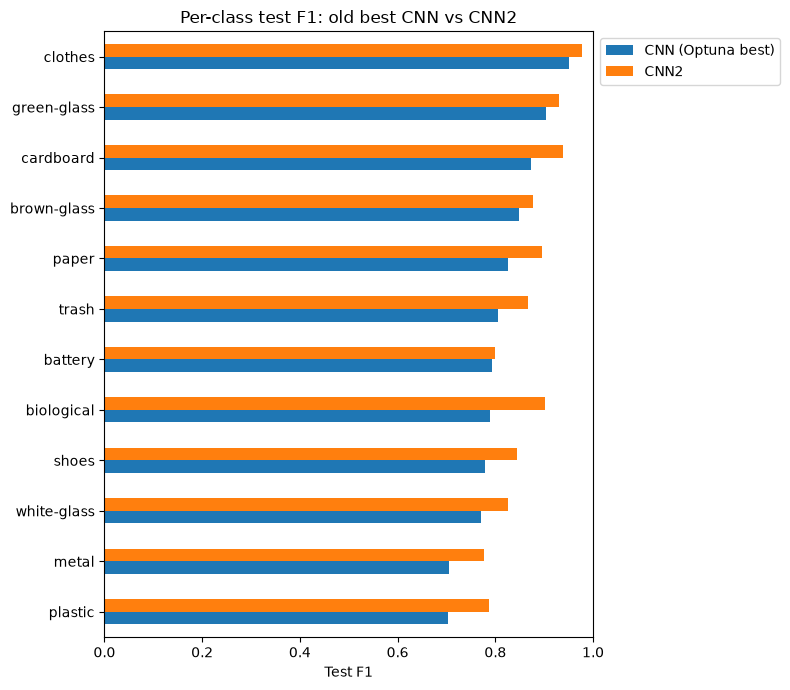

,,new,old
true,pred,,
battery,shoes,21,10
biological,shoes,14,7
shoes,clothes,12,19
brown-glass,shoes,12,6
battery,metal,10,6
plastic,trash,9,4
clothes,shoes,7,13
white-glass,plastic,7,13
metal,shoes,6,7


In [ ]:
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix

# 클래스별 test F1과 자주 틀리는 쌍을 기존 최종 모델과 CNN2로 비교하는 코드임
#  - 표 1: 클래스별 F1 (old = 기존 최종, new = CNN2 최종, diff = new − old) → 어느 클래스가 좋아졌는지 봄
#  - 그래프: 같은 내용을 막대로 그림 (클래스는 old F1이 낮은 순)
#  - 표 2: CNN2가 가장 많이 틀린 (실제 → 예측) 쌍 10개와, 같은 쌍을 기존 모델은 몇 장 틀렸는지
#    → EDA에서 예상한 혼동(white-glass↔plastic, paper↔cardboard, 유리끼리)과 shoes↔clothes 등이 줄었는지 확인함

old_name, new_name = best_run, cnn2_run
f1_cls = pd.DataFrame({
    'old': precision_recall_fscore_support(y_true_t, test_pred[old_name], labels = range(len(CLASSES)), zero_division = 0)[2],
    'new': precision_recall_fscore_support(y_true_t, test_pred[new_name], labels = range(len(CLASSES)), zero_division = 0)[2],
}, index = CLASSES).sort_values('old')
f1_cls['diff'] = f1_cls['new'] - f1_cls['old']
display(f1_cls.round(3).T)

ax = f1_cls[['old', 'new']].plot.barh(figsize = (8, 7))
ax.set_xlim(0, 1)
ax.set_xlabel('Test F1')
ax.set_title('Per-class test F1: old best CNN vs CNN2')
ax.legend(['CNN (Optuna best)', 'CNN2'], loc = 'upper left', bbox_to_anchor = (1, 1))
plt.tight_layout()
plt.show()

pairs2 = {}
for key, name in [('new', new_name), ('old', old_name)] :            # 모델마다 (실제, 예측) 장수 표를 만듦
    cm2 = pd.DataFrame(confusion_matrix(y_true_t, test_pred[name], labels = range(len(CLASSES))), index = CLASSES, columns = CLASSES)
    pairs2[key] = cm2.rename_axis(index = 'true', columns = 'pred').stack()
top_pairs = pd.DataFrame(pairs2)
top_pairs = top_pairs[top_pairs.index.get_level_values(0) != top_pairs.index.get_level_values(1)]   # 맞힌 것(대각선)은 뺌
display(top_pairs.sort_values('new', ascending = False).head(10))